# Privacy Auditing with One Training Run — Full JupyterLab Notebook

**Includes both Algorithm 1 (Black-Box) and Algorithm 2 (White-Box) auditing**

**Paper:** Steinke, Nasr & Jagielski (2023) — *Privacy Auditing with One (1) Training Run*

**This notebook is fully self-contained** — no external `.py` modules required.  
It runs on JupyterLab with unlimited resources (multi-GPU optional).

### What this notebook does
1. Downloads CIFAR-10 automatically  
2. Trains **N shadow models** with Differentially Private SGD (Opacus)  
3. Computes membership-inference scores for canary examples  
4. Runs the statistical audit to produce a **provable ε lower bound**  
5. Produces publication-quality plots

### Config to tune (§ 2 — Configuration)
All hyperparameters live in one cell. Start small (`NUM_SHADOW=2`, `NUM_EPOCHS=5`) to verify the pipeline, then scale up.

> **Network / SSL note (IITGN & similar institutional servers)**  
> Your JupyterLab server sits behind a TLS-intercepting proxy that re-signs
> outbound HTTPS with an `*.iitgn.ac.in` certificate.  `pip` rejects this
> because it expects `pypi.org`.  
> **The install cell below detects this automatically and retries with
> `--trusted-host` flags.**  If it still fails, run the one-liner shown in
> the error message from a terminal *before* starting JupyterLab, or use the
> `conda` alternative shown there.  
> All other cells are network-free once packages are installed.

In [1]:
import resource

# Try to force the notebook to raise its own ceiling
try:
    soft, hard = resource.getrlimit(resource.RLIMIT_NOFILE)
    resource.setrlimit(resource.RLIMIT_NOFILE, (hard, hard))
    new_soft, _ = resource.getrlimit(resource.RLIMIT_NOFILE)
    print(f"Successfully raised limit from {soft} to {new_soft}")
except Exception as e:
    print(f"Could not raise limit: {e}")

Successfully raised limit from 4096 to 524288


In [2]:
CFG = {
    "data_dir": "/data/govindu.srimaan/cifar10"
}

import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

print("Locked to GPU 0")

Locked to GPU 0


In [3]:
# ── 1. Install / verify dependencies ─────────────────────────────────────────
# This cell handles two common network environments:
#   (a) Normal internet access  →  plain pip install
#   (b) Institutional proxy (e.g. IITGN) that re-signs TLS with its own cert
#       →  pip install --trusted-host + index fallback
#
# The cell tries a normal install first; if it fails due to an SSL error it
# retries with --trusted-host flags and, optionally, a mirror URL.

import subprocess, sys, os

# ── User config ───────────────────────────────────────────────────────────────
# If your institute provides a local PyPI mirror, put its URL here:
INSTITUTE_MIRROR = None   # e.g. "https://pypi.iitgn.ac.in/simple"
# Leave None to fall back to the global PyPI with trust flags.

PACKAGES = [
    "opacus>=1.5",
    "torch>=2.3",
    "torchvision>=0.18",
    "scipy>=1.13",
    "tqdm",
    "matplotlib",
]

# ─────────────────────────────────────────────────────────────────────────────
def _run(cmd):
    return subprocess.run(cmd, capture_output=True, text=True)

def pip_install_normal(pkgs):
    return _run([sys.executable, "-m", "pip", "install", "-q"] + pkgs)

def pip_install_trusted(pkgs, mirror=None):
    """Install with SSL hostname trust bypass for institutional proxies."""
    trusted_hosts = [
        "--trusted-host", "pypi.org",
        "--trusted-host", "pypi.python.org",
        "--trusted-host", "files.pythonhosted.org",
    ]
    cmd = [sys.executable, "-m", "pip", "install", "-q"] + trusted_hosts + pkgs
    if mirror:
        cmd += ["--index-url", mirror]
    return _run(cmd)

# ── Step 1: try normal install ────────────────────────────────────────────────
print("Trying standard pip install …")
result = pip_install_normal(PACKAGES)

if result.returncode == 0:
    print("✓ All packages installed / already present.")
else:
    stderr = result.stderr + result.stdout
    if "SSLError" in stderr or "CertificateError" in stderr or "hostname" in stderr.lower():
        print("SSL/certificate issue detected (institutional proxy).")
        print("Retrying with --trusted-host flags …")
        result2 = pip_install_trusted(PACKAGES, mirror=INSTITUTE_MIRROR)
        if result2.returncode == 0:
            print("✓ Packages installed via trusted-host bypass.")
        else:
            print("Second attempt also failed. Error output:")
            print(result2.stderr[-2000:])
            print()
            print("── Manual fix options ───────────────────────────────────────")
            print("Option A: run in a terminal before launching JupyterLab:")
            print("  pip install --trusted-host pypi.org --trusted-host files.pythonhosted.org \\")
            print("    opacus>=1.5 torch>=2.3 torchvision>=0.18 scipy matplotlib tqdm")
            print()
            print("Option B: use conda (avoids pip SSL issues entirely):")
            print("  conda install -c pytorch -c conda-forge pytorch torchvision scipy matplotlib tqdm")
            print("  pip install --trusted-host pypi.org opacus>=1.5")
            print()
            print("Option C: set INSTITUTE_MIRROR in this cell to your institute PyPI mirror URL.")
            raise RuntimeError("Dependency installation failed — see instructions above.")
    else:
        print("Installation failed for a non-SSL reason. Error:")
        print(result.stderr[-2000:])
        raise RuntimeError("pip install failed.")

# ── Verify imports ────────────────────────────────────────────────────────────
import torch, torchvision, opacus, scipy, tqdm, matplotlib
print(f"  torch       {torch.__version__}")
print(f"  torchvision {torchvision.__version__}")
print(f"  opacus      {opacus.__version__}")
print(f"  scipy       {scipy.__version__}")


Trying standard pip install …
✓ All packages installed / already present.
  torch       2.5.1+cu124
  torchvision 0.20.1+cu124
  opacus      1.5.4
  scipy       1.15.3


In [4]:
# ── 2. Imports and device ────────────────────────────────────────────────────
# Targeting Python 3.10 / JupyterHub (/opt/jupyterhub/bin/python)
import os, math, copy, random, json, pathlib, collections, warnings, time, sys
warnings.filterwarnings("ignore")

import numpy as np
import scipy.stats
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.data
import torchvision
import torchvision.transforms as TF          # v1 API — always available
import torchvision.transforms.functional as TFF
import tqdm
import matplotlib.pyplot as plt
from opacus import PrivacyEngine
from opacus.utils.batch_memory_manager import BatchMemoryManager
from opacus.validators import ModuleValidator

os.environ["PYTORCH_ALLOC_CONF"] = "expandable_segments:True"

# ── torchvision.transforms.v2 compatibility shim ─────────────────────────────
# v2 was introduced in torchvision 0.15 and some servers have older versions.
# We define thin wrappers so the rest of the notebook uses a single API.
try:
    import torchvision.transforms.v2 as _T2
    _HAS_V2 = True
except ImportError:
    _HAS_V2 = False

class _Transforms:
    """Unified transform helpers that work on torch.Tensor inputs (uint8 or float)."""

    @staticmethod
    def to_float(x: torch.Tensor, dtype=torch.float32) -> torch.Tensor:
        """uint8 [0,255] → float [0,1]."""
        if x.dtype == torch.uint8:
            return x.to(dtype=dtype).div(255.0)
        return x.to(dtype=dtype)

    @staticmethod
    def normalize(x: torch.Tensor, mean, std) -> torch.Tensor:
        return TFF.normalize(x, mean=list(mean), std=list(std))

    @staticmethod
    def random_crop(x: torch.Tensor, size=32, padding=4) -> torch.Tensor:
        return TFF.pad(x, padding)
        # Then random crop
        _, h, w = x.shape
        padded = TFF.pad(x, padding)
        i = random.randint(0, 2 * padding)
        j = random.randint(0, 2 * padding)
        return padded[:, i:i+size, j:j+size]

    @staticmethod
    def random_hflip(x: torch.Tensor, p=0.5) -> torch.Tensor:
        if random.random() < p:
            return TFF.hflip(x)
        return x

    @staticmethod
    def to_image(x) -> torch.Tensor:
        """PIL Image → uint8 CHW tensor (or pass-through if already tensor)."""
        if isinstance(x, torch.Tensor):
            return x
        return TF.ToTensor()(x).mul(255).to(torch.uint8)

    @staticmethod
    def augment(x: torch.Tensor) -> torch.Tensor:
        x = _Transforms.random_crop(x, 32, 4)
        x = _Transforms.random_hflip(x)
        return x

TX = _Transforms()

# ── Device Setup for Parallel Shadow-Model Training ──────────────────────────

import os
import torch
import torchvision
import sys

# Select GPU manually per notebook/process
# Notebook 1 → GPU_ID = 0
# Notebook 2 → GPU_ID = 1

GPU_ID = 0

if torch.cuda.is_available():
    DEVICE = torch.device(f"cuda:{GPU_ID}")
    torch.cuda.set_device(GPU_ID)
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

DTYPE = torch.float32

NUM_GPUS = torch.cuda.device_count() if torch.cuda.is_available() else 0

# CIFAR-10 normalization constants
CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD  = (0.2023, 0.1994, 0.2010)

print(f"Python        {sys.version.split()[0]}")
print(f"PyTorch       {torch.__version__}")
print(f"torchvision   {torchvision.__version__}")
print(f"Using Device  {DEVICE}")
print(f"CUDA GPUs     {NUM_GPUS}")

if torch.cuda.is_available():
    print(f"Current GPU   {torch.cuda.get_device_name(GPU_ID)}")

Python        3.10.12
PyTorch       2.5.1+cu124
torchvision   0.20.1+cu124
Using Device  cuda:0
CUDA GPUs     1
Current GPU   NVIDIA L40S


---
## § 2 — Configuration

Edit the values below. All other cells read from this one dict.

In [5]:
import torch
import numpy as np
import os
import pathlib
from datetime import datetime

# Create experiment name with timestamp
# experiment_name = f"blackbox_audit_v2_{datetime.now().strftime('%Y%m%d_%H%M%S')}"
experiment_name = "blackbox_audit_v2_20260521_145010"
CFG = {
    # ── Experiment & Paths ──
    "experiment": experiment_name,
    "data_dir": pathlib.Path("./data"),
    "output_dir": pathlib.Path(f"./experiments/{experiment_name}"),
    
    # ── Audit (Algorithm 1) Parameters ──
    "num_canaries": 3000,         # Number of canaries to inject
    "num_shadow": 16,             # FULL AUDIT: 16 shadow models total
    "canary_type": "random_labels",  # Options: "random_labels", "blank_images", "clean"
    "seed": 2024,
    
    # ── DP-SGD Training ──
    "batch_size": 4096,
    "max_phys_batch": 1024,
    "num_epochs": 150,
    "learning_rate": 4.0,
    "noise_multiplier": 1.5,      # σ = 1.5 for moderate DP
    "max_grad_norm": 1.0,
    "delta": 1e-5,
    "num_workers": 4,
    
    # ── Audit Hyperparameters (set later) ──
    "k_plus": None,               # Will be set in cell 34
    "k_minus": None,
    "confidence_p": 0.05,
}

# Create output directories
CFG["output_dir"].mkdir(parents=True, exist_ok=True)
CFG["ckpt_dir"] = CFG["output_dir"] / "shadow"
CFG["ckpt_dir"].mkdir(parents=True, exist_ok=True)

# Add device for convenience
CFG["device"] = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Experiment: {experiment_name}")
print(f"Output:     {CFG['output_dir']}")
print(f"Checkpoints:{CFG['ckpt_dir']}")
print(f"Device:     {CFG['device']}")

Experiment: blackbox_audit_v2_20260521_145010
Output:     experiments/blackbox_audit_v2_20260521_145010
Checkpoints:experiments/blackbox_audit_v2_20260521_145010/shadow
Device:     cuda


In [6]:
import os

print(os.listdir(CFG["ckpt_dir"]))

['membership.npy', '6', '11', '7', '1', 'wb_membership.npy', '15', '9', 'canary_indices.npy', 'wb_shadow_scores.npy', '14', '12', '2', '0', '13', '8', '4', 'shadow_scores.npy', '10', '5', '3']


In [7]:
import os

for s in range(CFG["num_shadow"]):

    shadow_dir = CFG["ckpt_dir"] / str(s)

    print(f"\nShadow {s}")

    print(os.listdir(shadow_dir))


Shadow 0
['ema_epoch_150.pt', 'ema_epoch_50.pt', 'ema_model.pt', 'ema_latest.pt', 'ema_epoch_100.pt', 'w0_state.pt', 'training_log.json']

Shadow 1
['ema_epoch_150.pt', 'ema_epoch_50.pt', 'ema_model.pt', 'ema_latest.pt', 'ema_epoch_100.pt', 'w0_state.pt', 'training_log.json']

Shadow 2
['ema_epoch_150.pt', 'ema_epoch_50.pt', 'ema_model.pt', 'ema_latest.pt', 'ema_epoch_100.pt', 'w0_state.pt', 'training_log.json']

Shadow 3
['ema_epoch_150.pt', 'ema_epoch_50.pt', 'ema_model.pt', 'ema_latest.pt', 'ema_epoch_100.pt', 'w0_state.pt', 'training_log.json']

Shadow 4
['ema_epoch_150.pt', 'ema_epoch_50.pt', 'ema_model.pt', 'ema_latest.pt', 'ema_epoch_100.pt', 'w0_state.pt', 'training_log.json']

Shadow 5
['ema_epoch_150.pt', 'ema_epoch_50.pt', 'ema_model.pt', 'ema_latest.pt', 'ema_epoch_100.pt', 'w0_state.pt', 'training_log.json']

Shadow 6
['ema_epoch_150.pt', 'ema_epoch_50.pt', 'ema_model.pt', 'ema_latest.pt', 'ema_epoch_100.pt', 'w0_state.pt', 'training_log.json']

Shadow 7
['ema_epoch_150.p

In [8]:
import resource
soft, hard = resource.getrlimit(resource.RLIMIT_NOFILE)
print(f"Final Notebook Limit: {soft}")

Final Notebook Limit: 524288


---
## § 3 — Reproducibility & Seeds

In [9]:
# ── 4. Seed helpers ──────────────────────────────────────────────────────────
def setup_seeds(seed: int, deterministic: bool = True):
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    if deterministic:
        os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
        try:
            torch.use_deterministic_algorithms(True)
        except RuntimeError:
            pass  # some ops don't have deterministic kernels; skip silently
        os.environ["TF_CUDNN_DETERMINISTIC"] = "1"

def shadow_seed(global_seed: int, shadow_idx: int, num_shadow: int) -> int:
    return global_seed * (num_shadow + 1) + shadow_idx + 1

setup_seeds(CFG["seed"])
print(f"Global seed: {CFG['seed']}")

Global seed: 2024


In [10]:
import os
import tarfile
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset
import numpy as np
import random

# 1. SETUP PATHS - Based on your directory list, your data is likely in the 'data' folder
# We will check both the current directory and the 'data' subdirectory
POSSIBLE_DIRS = ["./", "./data"]
TAR_FILENAME = "cifar-10-python.tar.gz" 

found_path = None
for d in POSSIBLE_DIRS:
    test_path = os.path.join(d, TAR_FILENAME)
    if os.path.exists(test_path):
        found_path = d
        break

if found_path:
    DATA_DIR = found_path
    print(f"✅ Found {TAR_FILENAME} in: {DATA_DIR}")
else:
    # If not found, let's look at what is INSIDE the 'data' folder to help you
    print(f"❌ Could not find {TAR_FILENAME}")
    if os.path.exists("./data"):
        print("Contents of './data' folder:", os.listdir("./data"))
    DATA_DIR = "./data" # Defaulting to data folder

TAR_PATH = os.path.join(DATA_DIR, TAR_FILENAME)
EXTRACT_PATH = os.path.join(DATA_DIR, "cifar-10-batches-py")

# 2. EXTRACTION
if not os.path.exists(EXTRACT_PATH):
    if os.path.exists(TAR_PATH):
        print(f"Extracting {TAR_PATH}...")
        with tarfile.open(TAR_PATH, "r:gz") as tar:
            tar.extractall(path=DATA_DIR)
        print("Extraction complete.")
    else:
        print("Skipping extraction: Tar file not found or already extracted.")

# 3. TRANSFORMS
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# 4. LOAD DATASET
try:
    # IMPORTANT: root should be the folder that CONTAINS 'cifar-10-batches-py'
    trainset = torchvision.datasets.CIFAR10(root=DATA_DIR, train=True, download=False, transform=transform)
    testset  = torchvision.datasets.CIFAR10(root=DATA_DIR, train=False, download=False, transform=transform)
    print(f"🚀 SUCCESS: Dataset Loaded. Train size: {len(trainset)}")
except Exception as e:
    print(f"❌ Error loading dataset: {e}")
    print("Check if 'cifar-10-batches-py' exists inside your 'data' folder.")

✅ Found cifar-10-python.tar.gz in: ./data
🚀 SUCCESS: Dataset Loaded. Train size: 50000


In [11]:
import torchvision
import torchvision.transforms as transforms
import torch

print("Loading CIFAR-10 Dataset...")
# 1. Load the raw datasets
transform = transforms.ToTensor()
trainset = torchvision.datasets.CIFAR10(root=CFG["data_dir"], train=True, download=True, transform=transform)
testset  = torchvision.datasets.CIFAR10(root=CFG["data_dir"], train=False, download=True, transform=transform)

# 2. Extract raw tensors for the DataGenerator
print("Converting datasets to raw tensors...")
_train_xs = torch.stack([trainset[i][0] for i in range(len(trainset))])
_train_ys_clean = torch.tensor(trainset.targets)

_test_xs = torch.stack([testset[i][0] for i in range(len(testset))])
_test_ys = torch.tensor(testset.targets)

print(f"✅ Ready: _train_xs shape: {_train_xs.shape}")

Loading CIFAR-10 Dataset...
Files already downloaded and verified
Files already downloaded and verified
Converting datasets to raw tensors...
✅ Ready: _train_xs shape: torch.Size([50000, 3, 32, 32])


---
## § 4 — Dataset Generator (Canary Injection + IN/OUT Splits)

In [12]:
# ── 6. Canary + shadow-split generator ───────────────────────────────────────
class PrivacyAuditDataset(torch.utils.data.Dataset):
    def __init__(self, xs, ys, indices=None, transform=None):
        self.xs = xs
        self.ys = ys
        self.idx = (torch.arange(len(xs)) if indices is None
                    else torch.as_tensor(indices, dtype=torch.long))
        self.transform = transform

    def __len__(self):  return len(self.idx)

    def __getitem__(self, i):
        x = self.xs[self.idx[i]]
        y = self.ys[self.idx[i]]
        if self.transform:
            x = self.transform(x)
        return x, y

    def as_features_only(self, transform=None):
        return _FeaturesOnly(self.xs, self.idx, transform or self.transform)


class _FeaturesOnly(torch.utils.data.Dataset):
    def __init__(self, xs, idx, transform):
        self.xs = xs; self.idx = idx; self.transform = transform
    def __len__(self):  return len(self.idx)
    def __getitem__(self, i):
        x = self.xs[self.idx[i]]
        return self.transform(x) if self.transform else x


class DataGenerator:
    """Manages canary injection and per-shadow IN/OUT membership."""

    def __init__(self, train_xs, train_ys_clean, test_xs, test_ys,
                 num_shadow, num_canaries, canary_type, seed):
        self.train_xs       = train_xs
        self.train_ys_clean = train_ys_clean
        self.test_xs        = test_xs
        self.test_ys        = test_ys
        self.num_shadow     = num_shadow
        self.num_canaries   = num_canaries
        self.canary_type    = canary_type
        self.N              = len(train_xs)
        self.num_classes    = 10

        rng = np.random.default_rng(seed)

        # ── 1. IN/OUT splits (Algorithm 1: Independent Bernoulli Flips) ───────
        # Identify which samples are canaries
        self.canary_order = rng.permutation(self.N)
        canary_indices = self.canary_order[:num_canaries]
        
        # Start by asserting EVERY sample is IN the training set for all shadow models
        shadow_in = np.ones((self.N, num_shadow), dtype=bool)
        
        # For ONLY the canaries, flip an independent 50/50 coin for each shadow model
        # rng.integers(0, 2) generates independent 0s and 1s
        coin_flips = rng.integers(0, 2, size=(num_canaries, num_shadow)).astype(bool)
        shadow_in[canary_indices, :] = coin_flips
        
        self.shadow_in_mask = shadow_in     # (N, num_shadow) bool

        # ── 2. Noisy labels (used for label_noise canaries) ───────────────────
        label_changes = rng.integers(self.num_classes - 1, size=self.N)
        clean = train_ys_clean.numpy()
        self.noisy_ys = np.where(label_changes < clean, label_changes, label_changes + 1)

    # ------------------------------------------------------------------
    def get_canary_indices(self):
        return self.canary_order[: self.num_canaries]

    def _make_train_tensors(self):
        """Return (xs, ys) with canary modifications applied."""
        xs = self.train_xs.clone()
        ys = self.train_ys_clean.clone().numpy()
        ci = self.get_canary_indices()
        if self.canary_type == "label_noise":
            ys[ci] = self.noisy_ys[ci]
        elif self.canary_type == "blank_images":
            rng2 = np.random.default_rng(42)
            colors = rng2.integers(0, 256, size=(self.num_canaries, 3, 1, 1), dtype=np.uint8)
            xs[ci] = torch.from_numpy(
                np.broadcast_to(colors, (self.num_canaries, 3, 32, 32)).copy()
            )
            rand_labels = rng2.integers(0, self.num_classes, size=self.num_canaries)
            ys[ci] = rand_labels
        # "clean": no change
        return xs, torch.from_numpy(ys)

    def build_train_data(self, shadow_idx, transform=None):
        xs, ys = self._make_train_tensors()
        in_idx = np.where(self.shadow_in_mask[:, shadow_idx])[0]
        return PrivacyAuditDataset(xs, ys, indices=in_idx, transform=transform)

    def build_full_train_data(self, transform=None):
        xs, ys = self._make_train_tensors()
        return PrivacyAuditDataset(xs, ys, transform=transform)

    def build_test_data(self, transform=None):
        return PrivacyAuditDataset(self.test_xs, self.test_ys, transform=transform)

    def build_in_mask(self, shadow_idx):
        return torch.from_numpy(self.shadow_in_mask[:, shadow_idx])

    def is_in_mask(self, shadow_idx):
        """Alias used by scoring cells."""
        return self.build_in_mask(shadow_idx)


# Instantiate
data_gen = DataGenerator(
    train_xs=_train_xs, train_ys_clean=_train_ys_clean,
    test_xs=_test_xs,   test_ys=_test_ys,
    num_shadow=CFG["num_shadow"],
    num_canaries=CFG["num_canaries"],
    canary_type=CFG["canary_type"],
    seed=CFG["seed"],
)
ci = data_gen.get_canary_indices()
print(f"Canary indices (first 10): {ci[:10]}")
print(f"Average canary IN count per shadow model: {data_gen.shadow_in_mask[ci].mean():.3f}")

Canary indices (first 10): [ 6160  9086 18826 31124 13332 13007 24878 49531 30951 15368]
Average canary IN count per shadow model: 0.499


---
## § 5 — WideResNet-16-4 (Group-Norm, Opacus-compatible)

In [13]:
# ── 7. WideResNet ────────────────────────────────────────────────────────────
class WideBlock(nn.Module):
    def __init__(self, fin, fout, stride, expand, norm_fn, swap=True):
        super().__init__()
        self.swap = swap
        self.n1 = norm_fn(fin)
        self.c1 = nn.Conv2d(fin, fout, 3, 1, 1)
        self.n2 = norm_fn(fout)
        self.c2 = nn.Conv2d(fout, fout, 3, stride, 1)
        if stride != 1 or expand:
            if swap:
                self.skip = nn.Sequential(nn.ReLU(), norm_fn(fin),
                                          nn.Conv2d(fin, fout, 1, stride))
            else:
                self.skip = nn.Conv2d(fin, fout, 1, stride)
        else:
            self.skip = nn.Identity()

    def forward(self, x):
        if self.swap:
            h = self.c1(self.n1(F.relu(x)))
            h = self.c2(self.n2(F.relu(h)))
        else:
            h = self.c1(F.relu(self.n1(x)))
            h = self.c2(F.relu(self.n2(h)))
        return h + self.skip(x)


class WideResNet(nn.Module):
    def __init__(self, depth=16, widen=4, num_classes=10, swap=True):
        super().__init__()
        assert (depth - 4) % 6 == 0
        nb = (depth - 4) // 6
        fs = (16, 16*widen, 32*widen, 64*widen)

        def norm(c): return nn.GroupNorm(min(16, c), c)

        self.conv0  = nn.Conv2d(3, fs[0], 3, 1, 1)
        self.group1 = self._layer(fs[0], fs[1], 1, nb, norm, swap)
        self.group2 = self._layer(fs[1], fs[2], 2, nb, norm, swap)
        self.group3 = self._layer(fs[2], fs[3], 2, nb, norm, swap)
        self.norm_out = norm(fs[3])
        self.pool   = nn.AdaptiveAvgPool2d(1)
        self.flat   = nn.Flatten()
        self.fc     = nn.Linear(fs[3], num_classes)
        self.swap   = swap
        self._fin   = fs[3]
        self._init()

    def _layer(self, fin, fout, stride, n, norm_fn, swap):
        blocks = []
        for i in range(n):
            blocks.append(WideBlock(fin if i==0 else fout, fout,
                                    stride if i==0 else 1,
                                    fin != fout, norm_fn, swap))
        return nn.Sequential(*blocks)

    def _init(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                fi = max(1, m.weight.size(1) * m.weight.size(2) * m.weight.size(3))
                nn.init.trunc_normal_(m.weight, std=1/fi**0.5)
                if m.bias is not None: nn.init.zeros_(m.bias)
            elif isinstance(m, nn.GroupNorm):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                fi = max(1, m.weight.size(1))
                nn.init.trunc_normal_(m.weight, std=1/fi**0.5)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        h = self.conv0(x)
        h = self.group1(h); h = self.group2(h); h = self.group3(h)
        h = self.norm_out(F.relu(h)) if self.swap else F.relu(self.norm_out(h))
        return self.fc(self.flat(self.pool(h)))

    def replace_head(self, num_classes):
        self.fc = nn.Linear(self._fin, num_classes).to(self.fc.weight.device)

def build_model(num_classes=10):
    return WideResNet(depth=16, widen=4, num_classes=num_classes, swap=True).to(DEVICE)

# Quick smoke-test
_m = build_model()
_x = torch.randn(2, 3, 32, 32, device=DEVICE)
assert _m(_x).shape == (2, 10)
print(f"WideResNet-16-4: {sum(p.numel() for p in _m.parameters()):,} parameters")
del _m, _x

WideResNet-16-4: 2,838,922 parameters


---
## § 6 — DP-SGD Training Loop

In [14]:
# ── 8. Transforms and dataset wrapper ────────────────────────────────────────
# All transforms operate on uint8 CHW tensors (as loaded into memory).
# TX helper (defined in cell 2) provides float-conversion, normalise, augment.

class NormDataset(torch.utils.data.Dataset):
    """
    Wraps PrivacyAuditDataset; converts uint8 → normalised float on-the-fly.
    Optionally applies random augmentation (for training).
    """
    def __init__(self, ds: PrivacyAuditDataset, augment: bool = False):
        self.ds      = ds
        self.augment = augment

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, i):
        x, y = self.ds[i]
        x = TX.to_float(x, DTYPE)
        if self.augment:
            x = TX.augment(x)
        x = TX.normalize(x, CIFAR10_MEAN, CIFAR10_STD)
        return x, y


class InferenceDataset(torch.utils.data.Dataset):
    """Features-only dataset with normalisation; used during inference."""
    def __init__(self, ds: PrivacyAuditDataset):
        self.ds = ds

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, i):
        x, _ = self.ds[i]
        x = TX.to_float(x, DTYPE)
        x = TX.normalize(x, CIFAR10_MEAN, CIFAR10_STD)
        return x


In [15]:
# ── 9. EMA helper ────────────────────────────────────────────────────────────
import copy

def create_ema(model):
    ema = copy.deepcopy(model)
    for p in ema.parameters():
        p.detach_()
    return ema

def update_ema(model, ema, t, decay=0.9999):
    t2 = t
    # Ramp-up strategy: faster updates early on, settling to 'decay'
    eff = min(decay, (1 + t2) / (10 + t2))
    mp = dict(model.named_parameters())
    ep = dict(ema.named_parameters())
    for name in mp:
        ep[name].sub_((1.0 - eff) * (ep[name] - mp[name]))
    
    # Buffers (like Batchnorm stats) are copied directly
    mb = dict(model.named_buffers())
    eb = dict(ema.named_buffers())
    for name in mb:
        eb[name].copy_(mb[name])

In [16]:
import json
import time
import copy
import warnings

def train_shadow_model(shadow_idx: int, cfg: dict,
                       data_gen: DataGenerator,
                       verbose: bool = True):
    """
    Train one shadow model with DP-SGD, saving continuous progress.
    """
    ckpt_dir  = cfg["ckpt_dir"] / str(shadow_idx)
    ckpt_ema  = ckpt_dir / "ema_model.pt"
    ckpt_w0   = ckpt_dir / "w0_state.pt"
    stats_file = ckpt_dir / "training_log.json"

    if ckpt_ema.exists() and ckpt_w0.exists():
        print(f"  [shadow {shadow_idx}] Checkpoint found — loading.")
        ema   = torch.load(ckpt_ema, map_location=DEVICE, weights_only=False)
        w0_sd = torch.load(ckpt_w0,  map_location="cpu",  weights_only=True)
        return ema, w0_sd

    ckpt_dir.mkdir(parents=True, exist_ok=True)
    setup_seeds(shadow_seed(cfg["seed"], shadow_idx, cfg["num_shadow"]))

    # ── Dataset ──────────────────────────────────────────────────────────────
    raw_ds  = data_gen.build_train_data(shadow_idx)
    train_ds = raw_ds
    loader   = torch.utils.data.DataLoader(
        train_ds,
        batch_size=cfg["batch_size"],
        shuffle=True,
        num_workers=cfg["num_workers"],
        drop_last=False,
        persistent_workers=(cfg["num_workers"] > 0),
        pin_memory=True,
    )

    # ── Model (single GPU for Opacus compatibility) ──────────────────────────
    base_model = WideResNet(depth=16, widen=4, num_classes=10).to(DEVICE)
    model = ModuleValidator.fix(base_model)
    errs  = ModuleValidator.validate(model, strict=False)
    if errs:
        raise RuntimeError(f"Opacus validation errors: {errs}")

    # ── Save w_0 ─────────────────────────────────────────────────────────────
    w0_state = copy.deepcopy(model.state_dict())
    w0_state_cpu = {k: v.cpu() for k, v in w0_state.items()}
    torch.save(w0_state_cpu, ckpt_w0)

    # ── Optimiser + Opacus ───────────────────────────────────────────────────
    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=cfg["learning_rate"],
        momentum=0.0,
        weight_decay=0.0,
    )
    loss_fn = nn.CrossEntropyLoss(reduction="mean")

    with warnings.catch_warnings():
        warnings.filterwarnings("ignore")
        pe = PrivacyEngine()
        model, optimizer, loader = pe.make_private(
            module=model,
            optimizer=optimizer,
            data_loader=loader,
            noise_multiplier=cfg["noise_multiplier"],
            max_grad_norm=cfg["max_grad_norm"],
        )

    ema        = create_ema(model)
    num_updates = 0
    log_every  = max(1, cfg["num_epochs"] // 10)
    
    training_history = []

    # ── Training loop ─────────────────────────────────────────────────────────
    for epoch in range(cfg["num_epochs"]):
        model.train()
        with BatchMemoryManager(
            data_loader=loader,
            max_physical_batch_size=cfg["max_phys_batch"],
            optimizer=optimizer,
        ) as opt_loader:
            epoch_loss = epoch_n = 0

            for bx, by in opt_loader:
                bx = bx.to(DEVICE)
                by = by.to(DEVICE)
                optimizer.zero_grad(set_to_none=True)

                loss = loss_fn(model(bx), by)
                loss.backward()

                will_update = not optimizer._check_skip_next_step(pop_next=False)
                optimizer.step()
                if will_update:
                    num_updates += 1
                    update_ema(model, ema, num_updates)

                epoch_loss += loss.item() * bx.size(0)
                epoch_n    += bx.size(0)

        # ── INTERMEDIATE SAVING LOGIC ──
        eps = pe.get_epsilon(cfg["delta"])
        avg_loss = epoch_loss / epoch_n
        
        # 1. Save stats to JSON
        training_history.append({"epoch": epoch + 1, "loss": avg_loss, "epsilon": eps})
        with open(stats_file, "w") as f:
            json.dump(training_history, f, indent=4)

        # 2. Overwrite latest backup
        torch.save(ema, ckpt_dir / "ema_latest.pt")
        
        # 3. Save Milestone checkpoints (e.g., at epoch 50, 100)
        if (epoch + 1) % 50 == 0:
            torch.save(ema, ckpt_dir / f"ema_epoch_{epoch+1}.pt")

        if verbose or (epoch + 1) % log_every == 0:
            print(f"    epoch {epoch+1:3d}/{cfg['num_epochs']}  loss={avg_loss:.4f}  ε={eps:.4f}")

    # Final Save
    ema.eval()
    torch.save(ema, ckpt_ema)
    print(f"  [shadow {shadow_idx}] finished & saved → {ckpt_dir}")
    return ema, w0_state_cpu


---
## § 7 — Train All Shadow Models

In [17]:
CKPT_DIR = CFG["ckpt_dir"]

In [18]:
# ── Train shadow models on GPU 0 ─────────────────────────────────────────────
# GPU 0 trains models 0-7 (first half)
# GPU 1 (run separate notebook) trains models 8-15 (second half)

import time
import gc
import multiprocessing

# Clean up any lingering processes from previous runs
gc.collect()
torch.cuda.empty_cache()
for p in multiprocessing.active_children():
    p.terminate()

trained_models = {}
w0_states = {}  # Store w_0 (initial weights)

# GPU 0 assignment
START_IDX = 0
END_IDX = 8  # GPU 0 trains shadows 0-7

print(f"\n{'='*70}")
print(f"GPU 0: Training shadow models {START_IDX} to {END_IDX-1}")
print(f"{'='*70}\n")

t0 = time.time()

for s in range(START_IDX, END_IDX):
    print(f"\n─── Shadow model {s+1}/{CFG['num_shadow']} ───")
    
    # train_shadow_model returns (ema_model, w0_state_dict)
    ema, w0_sd = train_shadow_model(s, CFG, data_gen, verbose=False)
    
    trained_models[s] = ema
    w0_states[s] = w0_sd
    
    # Cleanup after each model
    gc.collect()
    torch.cuda.empty_cache()

elapsed = (time.time() - t0) / 60
print(f"\n{'='*70}")
print(f"GPU 0 completed models {START_IDX}-{END_IDX-1} in {elapsed:.1f} minutes")
print(f"{'='*70}")
print(f"✓ Stored {len(trained_models)} models in memory")
print(f"✓ Checkpoints saved to: {CFG['ckpt_dir']}")


GPU 0: Training shadow models 0 to 7


─── Shadow model 1/16 ───
  [shadow 0] Checkpoint found — loading.

─── Shadow model 2/16 ───
  [shadow 1] Checkpoint found — loading.

─── Shadow model 3/16 ───
  [shadow 2] Checkpoint found — loading.

─── Shadow model 4/16 ───
  [shadow 3] Checkpoint found — loading.

─── Shadow model 5/16 ───
  [shadow 4] Checkpoint found — loading.

─── Shadow model 6/16 ───
  [shadow 5] Checkpoint found — loading.

─── Shadow model 7/16 ───
  [shadow 6] Checkpoint found — loading.

─── Shadow model 8/16 ───
  [shadow 7] Checkpoint found — loading.

GPU 0 completed models 0-7 in 0.0 minutes
✓ Stored 8 models in memory
✓ Checkpoints saved to: experiments/blackbox_audit_v2_20260521_145010/shadow


In [19]:
# ── Cleanup after training loop (run IMMEDIATELY after cell 23) ──
import gc
import multiprocessing

print("\nCleaning up resources...")

# Garbage collect
gc.collect()
torch.cuda.empty_cache()

# Terminate any lingering worker processes
for p in multiprocessing.active_children():
    p.terminate()
    p.join(timeout=2)

print("✓ Resources cleaned. Ready for scoring phase.")


Cleaning up resources...
✓ Resources cleaned. Ready for scoring phase.


In [20]:
import shutil
from pathlib import Path

# The two experiment dirs from your output
DIR_A = Path("experiments/blackbox_audit_v2_20260521_144018/shadow")  # models 8-15
DIR_B = Path("experiments/blackbox_audit_v2_20260521_145010/shadow")  # models 0-7

# Pick DIR_B as the canonical one (has 0-7), copy 8-15 into it
for s in range(8, 16):
    src = DIR_A / str(s)
    dst = DIR_B / str(s)
    if src.exists() and not dst.exists():
        shutil.copytree(src, dst)
        print(f"  Copied shadow {s}: {src} → {dst}")
    elif dst.exists():
        print(f"  Shadow {s} already exists in dst, skipping")
    else:
        print(f"  ⚠️  Shadow {s} missing from {src}")

  Shadow 8 already exists in dst, skipping
  Shadow 9 already exists in dst, skipping
  Shadow 10 already exists in dst, skipping
  Shadow 11 already exists in dst, skipping
  Shadow 12 already exists in dst, skipping
  Shadow 13 already exists in dst, skipping
  Shadow 14 already exists in dst, skipping
  Shadow 15 already exists in dst, skipping


---
## § 8 — Score Computation

In [21]:
# ── 12. Inference helper ──────────────────────────────────────────────────────
import gc

@torch.no_grad()
def predict_logits(model: nn.Module, dataset, batch_size=512) -> torch.Tensor:
    """
    Run model on `dataset` (features only) and return logits shape (N, C).
    
    CRITICAL: num_workers=0 prevents "Too many open files" error during scoring.
    """
    model.eval()
    
    # 🟢 FIX: persistent_workers=False, num_workers=0 prevents fd leaks
    loader = torch.utils.data.DataLoader(
        dataset, 
        batch_size=batch_size, 
        shuffle=False,
        num_workers=0,      # ← MUST be 0 for scoring
        pin_memory=True,
        persistent_workers=False
    )
    
    logits_list = []
    with torch.no_grad():
        for bx in loader:
            bx = bx.to(CFG["device"])
            logits = model(bx)
            logits_list.append(logits.detach().cpu())
    
    return torch.cat(logits_list, dim=0)  # (N, num_classes)


class InferenceDataset(torch.utils.data.Dataset):
    """
    Features-only dataset for scoring (no augmentation, deterministic).
    """
    def __init__(self, ds: PrivacyAuditDataset):
        self.ds = ds
    
    def __len__(self):
        return len(self.ds)
    
    def __getitem__(self, i):
        x, _ = self.ds[i]
        # No labels, no augmentation — just return normalized features
        return self.normalize(x)
    
    @staticmethod
    def normalize(x):
        """uint8 CHW [0,255] → float32 CHW normalized"""
        if x.dtype == torch.uint8:
            x = x.to(torch.float32) / 255.0
        # CIFAR-10 channel-wise normalization
        CIFAR_MEAN = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
        CIFAR_STD = torch.tensor([0.2023, 0.1994, 0.2010]).view(3, 1, 1)
        return (x - CIFAR_MEAN) / CIFAR_STD

In [22]:
# ✅ Load all checkpoints from disk (after BOTH GPUs finish training)

print("\nLoading all shadow model checkpoints from disk...\n")

w0_states = {}  # Initialize if not already in memory

for s in range(CFG["num_shadow"]):
    ckpt_base = CFG["ckpt_dir"] / str(s)
    ckpt_ema  = ckpt_base / "ema_model.pt"
    ckpt_w0   = ckpt_base / "w0_state.pt"
    
    if ckpt_ema.exists() and ckpt_w0.exists():
        print(f"  Shadow {s:2d}: Loading... ", end="", flush=True)
        
        trained_models[s] = torch.load(
            ckpt_ema, 
            map_location=CFG["device"], 
            weights_only=False
        )
        
        w0_states[s] = torch.load(
            ckpt_w0, 
            map_location="cpu", 
            weights_only=True
        )
        
        print("✓")
    else:
        print(f"  ⚠️  Shadow {s:2d}: MISSING checkpoint!")
        if not ckpt_ema.exists():
            print(f"       Missing: {ckpt_ema}")
        if not ckpt_w0.exists():
            print(f"       Missing: {ckpt_w0}")

print(f"\n✓ Loaded {len(trained_models)} shadow models and {len(w0_states)} w0 states")
print(f"✓ Ready for scoring phase")


Loading all shadow model checkpoints from disk...

  Shadow  0: Loading... ✓
  Shadow  1: Loading... ✓
  Shadow  2: Loading... ✓
  Shadow  3: Loading... ✓
  Shadow  4: Loading... ✓
  Shadow  5: Loading... ✓
  Shadow  6: Loading... ✓
  Shadow  7: Loading... ✓
  Shadow  8: Loading... ✓
  Shadow  9: Loading... ✓
  Shadow 10: Loading... ✓
  Shadow 11: Loading... ✓
  Shadow 12: Loading... ✓
  Shadow 13: Loading... ✓
  Shadow 14: Loading... ✓
  Shadow 15: Loading... ✓

✓ Loaded 16 shadow models and 16 w0 states
✓ Ready for scoring phase


In [23]:
# ── 13. Compute membership scores: Score(x) = loss(w_0, x) - loss(w_T, x) ──
import gc
import numpy as np

print("="*70)
print("SCORING PHASE: Computing loss(w_0, x) - loss(w_T, x)")
print("="*70)

# Build full dataset with canary modifications applied
print("\nBuilding full-train dataset (with canary labels applied)...")
full_ds = data_gen.build_full_train_data()

# Get canary indices and labels
canary_idx = torch.from_numpy(data_gen.get_canary_indices().astype("int64"))
all_ys = torch.stack([full_ds[i][1] for i in range(len(full_ds))])

N_CANARY = len(canary_idx)
N_SHADOW = CFG["num_shadow"]

print(f"✓ Full dataset: {len(full_ds)} examples")
print(f"✓ Canaries: {N_CANARY}")
print(f"✓ Shadow models: {N_SHADOW}")
print(f"\nScoring canaries across all shadow models...\n")

# Create inference dataset (no augmentation, deterministic)
feat_ds = InferenceDataset(full_ds)

# Storage for scores and membership
shadow_scores = torch.zeros(N_SHADOW, N_CANARY)
membership = torch.zeros(N_SHADOW, N_CANARY, dtype=torch.bool)

# ──────────────────────────────────────────────────────────────────────────
# SCORING LOOP: For each shadow model, compute loss_w0 and loss_wT
# ──────────────────────────────────────────────────────────────────────────

for s in range(N_SHADOW):
    ckpt_base = CFG["ckpt_dir"] / str(s)
    ckpt_ema = ckpt_base / "ema_model.pt"
    ckpt_w0 = ckpt_base / "w0_state.pt"
    
    # Check both files exist
    if not ckpt_ema.exists() or not ckpt_w0.exists():
        print(f"  ⚠️  Shadow {s:2d}: Missing checkpoints, skipping")
        continue
    
    print(f"  Shadow {s:2d}: ", end="", flush=True)
    
    # ── STEP 1: Load w_0 and compute loss(w_0, x) for all examples ────────
    w0_state = w0_states[s] if s in w0_states else torch.load(
        ckpt_w0, map_location="cpu", weights_only=True
    )
    
    w0_model = build_model()
    w0_model.load_state_dict(w0_state, strict=True)
    w0_model.to(CFG["device"])
    w0_model.eval()
    
    # Compute logits at w_0
    initial_logits = predict_logits(w0_model, feat_ds, batch_size=512)
    initial_loss = F.cross_entropy(
        initial_logits.to(CFG["device"]), 
        all_ys.to(CFG["device"]), 
        reduction="none"
    ).detach().cpu()
    
    del w0_model, initial_logits
    gc.collect()
    torch.cuda.empty_cache()
    
    # ── STEP 2: Load w_T (EMA) and compute loss(w_T, x) ────────────────────
    final_model = trained_models[s] if s in trained_models else torch.load(
        ckpt_ema, map_location=CFG["device"], weights_only=False
    )
    final_model.to(CFG["device"])
    final_model.eval()
    
    # Compute logits at w_T
    final_logits = predict_logits(final_model, feat_ds, batch_size=512)
    final_loss = F.cross_entropy(
        final_logits.to(CFG["device"]), 
        all_ys.to(CFG["device"]), 
        reduction="none"
    ).detach().cpu()
    
    del final_model, final_logits
    gc.collect()
    torch.cuda.empty_cache()
    
    # ── STEP 3: Compute score = loss(w_0, x) - loss(w_T, x) ────────────────
    score_full = initial_loss - final_loss  # (50000,)
    
    # Extract canary scores and membership
    shadow_scores[s] = score_full[canary_idx].cpu()
    membership[s] = data_gen.is_in_mask(s)[canary_idx].cpu()
    
    # Diagnostics
    nin = membership[s].sum().item()
    nout = N_CANARY - nin
    s_in = shadow_scores[s][membership[s]].mean().item()
    s_out = shadow_scores[s][~membership[s]].mean().item()
    
    print(f"IN={nin:4d}  OUT={nout:4d}  "
          f"score_in={s_in:+.4f}  score_out={s_out:+.4f}  Δ={s_in-s_out:+.4f}")

print("\n✓ Scoring complete.")

# Save to disk
scores_path = CFG["ckpt_dir"] / "shadow_scores.npy"
member_path = CFG["ckpt_dir"] / "membership.npy"
canary_path = CFG["ckpt_dir"] / "canary_indices.npy"

np.save(scores_path, shadow_scores.numpy())
np.save(member_path, membership.numpy())
np.save(canary_path, canary_idx.numpy())

print(f"✓ Saved scores     → {scores_path}")
print(f"✓ Saved membership → {member_path}")
print(f"✓ Saved canary idx → {canary_path}")

SCORING PHASE: Computing loss(w_0, x) - loss(w_T, x)

Building full-train dataset (with canary labels applied)...
✓ Full dataset: 50000 examples
✓ Canaries: 3000
✓ Shadow models: 16

Scoring canaries across all shadow models...

  Shadow  0: IN=1475  OUT=1525  score_in=+0.2611  score_out=+0.2335  Δ=+0.0276
  Shadow  1: IN=1522  OUT=1478  score_in=-1.0262  score_out=-1.0543  Δ=+0.0281
  Shadow  2: IN=1520  OUT=1480  score_in=-0.1893  score_out=-0.2807  Δ=+0.0913
  Shadow  3: IN=1513  OUT=1487  score_in=+0.1141  score_out=+0.0186  Δ=+0.0954
  Shadow  4: IN=1489  OUT=1511  score_in=-0.2536  score_out=-0.3837  Δ=+0.1301
  Shadow  5: IN=1484  OUT=1516  score_in=+0.4109  score_out=-0.1112  Δ=+0.5220
  Shadow  6: IN=1468  OUT=1532  score_in=+0.6751  score_out=+0.4719  Δ=+0.2032
  Shadow  7: IN=1528  OUT=1472  score_in=+0.5668  score_out=+0.2704  Δ=+0.2964
  Shadow  8: IN=1493  OUT=1507  score_in=+0.3851  score_out=+0.4274  Δ=-0.0423
  Shadow  9: IN=1502  OUT=1498  score_in=-3.2276  score_out=

In [24]:
import os
from pathlib import Path

base = CFG["ckpt_dir"]

print(base)

for s in range(CFG["num_shadow"]):
    p = base / str(s)

    print(f"\nShadow {s}")

    if p.exists():
        print("  Exists")

        for f in p.iterdir():
            print("   ", f.name)
    else:
        print("  Missing directory")

experiments/blackbox_audit_v2_20260521_145010/shadow

Shadow 0
  Exists
    ema_epoch_150.pt
    ema_epoch_50.pt
    ema_model.pt
    ema_latest.pt
    ema_epoch_100.pt
    w0_state.pt
    training_log.json

Shadow 1
  Exists
    ema_epoch_150.pt
    ema_epoch_50.pt
    ema_model.pt
    ema_latest.pt
    ema_epoch_100.pt
    w0_state.pt
    training_log.json

Shadow 2
  Exists
    ema_epoch_150.pt
    ema_epoch_50.pt
    ema_model.pt
    ema_latest.pt
    ema_epoch_100.pt
    w0_state.pt
    training_log.json

Shadow 3
  Exists
    ema_epoch_150.pt
    ema_epoch_50.pt
    ema_model.pt
    ema_latest.pt
    ema_epoch_100.pt
    w0_state.pt
    training_log.json

Shadow 4
  Exists
    ema_epoch_150.pt
    ema_epoch_50.pt
    ema_model.pt
    ema_latest.pt
    ema_epoch_100.pt
    w0_state.pt
    training_log.json

Shadow 5
  Exists
    ema_epoch_150.pt
    ema_epoch_50.pt
    ema_model.pt
    ema_latest.pt
    ema_epoch_100.pt
    w0_state.pt
    training_log.json

Shadow 6
  Exists
    

SCORE DIAGNOSTIC

Shadow 0 score statistics:
  All scores:      min=-16.7844, max=2.9358, mean=0.2471
  IN scores:       min=-16.7844, max=2.8076, mean=0.2611
  OUT scores:      min=-13.9991, max=2.9358, mean=0.2335
  Δ mean (IN-OUT): 0.0276

✓ Scores have nonzero variance: 10.2721


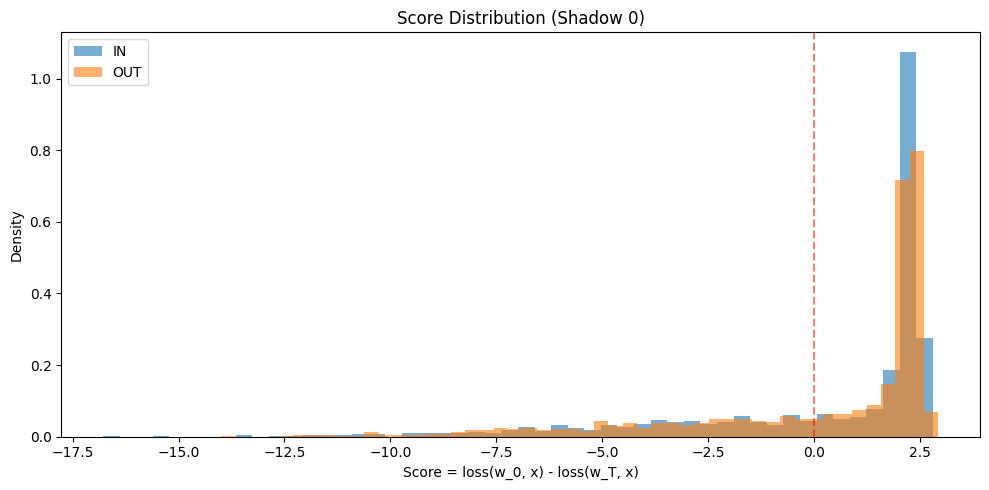


Plot saved to score_diagnostic.png


In [25]:
# ── DIAGNOSTIC: Inspect score distributions ──────────────────────────────────
import matplotlib.pyplot as plt

print("=" * 70)
print("SCORE DIAGNOSTIC")
print("=" * 70)

# Look at shadow 0 in detail
s = 0
scores_s = shadow_scores[s]
member_s = membership[s]

print(f"\nShadow {s} score statistics:")
print(f"  All scores:      min={scores_s.min():.4f}, max={scores_s.max():.4f}, mean={scores_s.mean():.4f}")
print(f"  IN scores:       min={scores_s[member_s].min():.4f}, max={scores_s[member_s].max():.4f}, mean={scores_s[member_s].mean():.4f}")
print(f"  OUT scores:      min={scores_s[~member_s].min():.4f}, max={scores_s[~member_s].max():.4f}, mean={scores_s[~member_s].mean():.4f}")
print(f"  Δ mean (IN-OUT): {scores_s[member_s].mean() - scores_s[~member_s].mean():.4f}")

# Check if all scores are zero (would indicate a loading or computation bug)
if scores_s.abs().sum() < 1e-6:
    print("\n⚠️  WARNING: All scores are zero! Check if w_0 and w_T are being loaded correctly.")
else:
    print(f"\n✓ Scores have nonzero variance: {scores_s.var():.4f}")

# Histogram
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(scores_s[member_s].numpy(), bins=50, alpha=0.6, label="IN", density=True)
ax.hist(scores_s[~member_s].numpy(), bins=50, alpha=0.6, label="OUT", density=True)
ax.set_xlabel("Score = loss(w_0, x) - loss(w_T, x)")
ax.set_ylabel("Density")
ax.set_title(f"Score Distribution (Shadow {s})")
ax.legend()
ax.axvline(0, color='red', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("score_diagnostic.png", dpi=100)
plt.show()

print(f"\nPlot saved to score_diagnostic.png")
print("=" * 70)

In [26]:
# ── SANITY CHECK: Verify loss computation ────────────────────────────────────
print("\n" + "=" * 70)
print("LOSS SANITY CHECK")
print("=" * 70)

s = 0
ckpt_base = CFG["ckpt_dir"] / str(s)
ckpt_w0   = ckpt_base / "w0_state.pt"
ckpt_ema  = ckpt_base / "ema_latest.pt"

# Load w_0
w0_state = torch.load(ckpt_w0, map_location="cpu", weights_only=True)
w0_model = build_model()
w0_model.load_state_dict(w0_state, strict=True)
w0_model.eval()

# Load w_T
ema_model = torch.load(ckpt_ema, map_location=CFG["device"], weights_only=False)
ema_model.eval()

# Compute losses on a SMALL SAMPLE (first 100 canaries)
test_idx = canary_idx[:100]
test_xs = torch.stack([feat_ds[int(i)] for i in test_idx])  # (100, 3, 32, 32)
test_ys = all_ys[test_idx]  # (100,)

with torch.no_grad():
    w0_logits = w0_model(test_xs.to(DEVICE))
    w0_loss = F.cross_entropy(w0_logits, test_ys.to(DEVICE), reduction="none").cpu()
    
    ema_logits = ema_model(test_xs.to(DEVICE))
    ema_loss = F.cross_entropy(ema_logits, test_ys.to(DEVICE), reduction="none").cpu()

score_sample = w0_loss - ema_loss

print(f"\nOn {len(test_idx)} canary examples:")
print(f"  w_0 loss:    min={w0_loss.min():.4f}, max={w0_loss.max():.4f}, mean={w0_loss.mean():.4f}")
print(f"  w_T loss:    min={ema_loss.min():.4f}, max={ema_loss.max():.4f}, mean={ema_loss.mean():.4f}")
print(f"  Score:       min={score_sample.min():.4f}, max={score_sample.max():.4f}, mean={score_sample.mean():.4f}")

# Check: if w_T is randomly initialized, it should have similar loss to w_0
# If w_T was trained, loss should be lower → score should be positive
print(f"\n  Expected: w_T loss < w_0 loss (because model was trained)")
print(f"  Actual:   w_T mean ({ema_loss.mean():.4f}) vs w_0 mean ({w0_loss.mean():.4f})")
print(f"  Training helped? {ema_loss.mean() < w0_loss.mean()}")

print("=" * 70)


LOSS SANITY CHECK

On 100 canary examples:
  w_0 loss:    min=1.9296, max=2.7376, mean=2.3093
  w_T loss:    min=0.0000, max=14.3502, mean=2.2312
  Score:       min=-12.1490, max=2.5983, mean=0.0781

  Expected: w_T loss < w_0 loss (because model was trained)
  Actual:   w_T mean (2.2312) vs w_0 mean (2.3093)
  Training helped? True


---
## § 8b — White-Box Score Computation (Algorithm 2)

> **Algorithm 2 — White-Box Auditing** (Steinke, Nasr & Jagielski 2023)
>
> The **white-box** score exploits gradient information that is inaccessible
> to a black-box adversary but *is* available when the auditor has full
> model access.
>
> ### Score definition
> For each canary example **x** with true label **y**, the white-box score is:
>
> $$\text{Score}_{\text{WB}}(x) = \langle \nabla_w \mathcal{L}(w_0,\, x),\; w_T - w_0 \rangle$$
>
> Intuitively:
> - **∇_w L(w₀, x)**: the loss gradient at initialisation — the direction the
>   model *would have* moved to fit **x**.
> - **w_T − w₀**: the actual parameter update after training.
> - Their **dot product** measures how much the training trajectory aligned with
>   fitting **x**, i.e. how likely **x** was IN the training set.
>
> ### Why white-box is stronger
> The black-box score uses only scalar losses; white-box uses the full gradient
> (millions of scalars). This yields a strictly more powerful membership test
> and a tighter (higher) ε lower bound for the same number of shadow models
> and canaries.
>
> ### Memory note
> Computing gradients for every canary in one pass requires O(|canary| × |params|)
> memory. The cell below processes canaries in mini-batches and accumulates the
> dot product incrementally to stay within GPU memory.


In [27]:
# ── Algorithm 2: White-Box Score = <∇_w L(w_0, x),  w_T - w_0> ──────────────
# Reference: Steinke, Nasr & Jagielski 2023, Section 3 / Algorithm 2
#
# Implementation strategy
# ───────────────────────
# 1. For each shadow model s:
#    a. Load w_0 (initial weights) and w_T (EMA weights after training).
#    b. Compute Δw = w_T - w_0  (flattened parameter difference vector).
#    c. For each canary x_i in mini-batches:
#         grad_i = ∇_w L(w_0, x_i)  (per-sample gradient at w_0)
#         score_i = dot(grad_i, Δw)
# 2. Use the same statistical audit (Algorithm 1 statistics) on these scores.

import gc
import math
import numpy as np
import torch
import torch.nn.functional as F

print("=" * 70)
print("WHITE-BOX SCORING: Score(x) = <∇L(w_0, x),  w_T - w_0>")
print("=" * 70)

# ── Helpers ──────────────────────────────────────────────────────────────────

def flatten_params(model):
    """Return a 1-D float32 CPU tensor of all trainable parameters."""
    return torch.cat([p.detach().cpu().float().view(-1)
                      for p in model.parameters()])


def compute_wb_scores_for_shadow(
    shadow_idx: int,
    data_gen,
    feat_ds,
    all_ys,
    canary_idx,
    cfg: dict,
    mini_batch: int = 32,
) -> torch.Tensor:
    """
    Compute white-box scores for all canaries under shadow model `shadow_idx`.

    Returns a 1-D tensor of shape (N_CANARY,) with scores
        Score(x_i) = <∇_w L(w_0, x_i), w_T - w_0>
    """
    ckpt_base = cfg["ckpt_dir"] / str(shadow_idx)
    ckpt_ema  = ckpt_base / "ema_model.pt"
    ckpt_w0   = ckpt_base / "w0_state.pt"

    if not ckpt_ema.exists() or not ckpt_w0.exists():
        print(f"  Shadow {shadow_idx:2d}: MISSING — skipping")
        return None

    device = cfg["device"]

    # ── 1. Load w_0 ──────────────────────────────────────────────────────────
    w0_state = torch.load(ckpt_w0, map_location="cpu", weights_only=True)
    w0_model = build_model()
    w0_model.load_state_dict(w0_state, strict=True)
    w0_model.to(device)
    w0_model.train()   # keep BatchNorm in train mode so grads are well-defined
    for p in w0_model.parameters():
        p.requires_grad_(True)

    # ── 2. Load w_T and compute Δw = w_T - w_0 ───────────────────────────────
    wT_model = torch.load(ckpt_ema, map_location=device, weights_only=False)
    wT_model.eval()

    w0_flat = flatten_params(w0_model)   # (P,)
    wT_flat = flatten_params(wT_model)   # (P,)
    delta_w  = (wT_flat - w0_flat).to(device)   # stays on GPU as a 1-D vector

    del wT_model, w0_flat, wT_flat
    gc.collect(); torch.cuda.empty_cache()

    # ── 3. Per-sample gradient dot products in mini-batches ───────────────────
    N_CANARY   = len(canary_idx)
    wb_scores  = torch.zeros(N_CANARY, dtype=torch.float32)

    for start in range(0, N_CANARY, mini_batch):
        end       = min(start + mini_batch, N_CANARY)
        batch_idx = canary_idx[start:end]           # global dataset indices
        n_batch   = len(batch_idx)

        # Gather features and labels for this mini-batch
        xs = torch.stack([feat_ds[int(i)] for i in batch_idx]).to(device)
        ys = all_ys[batch_idx].to(device)

        # Compute per-sample gradients via one-sample-at-a-time loop
        # (functorch vmap would be faster, but this works without extra deps)
        batch_dots = torch.zeros(n_batch, dtype=torch.float32)
        for j in range(n_batch):
            w0_model.zero_grad(set_to_none=True)
            logit = w0_model(xs[j].unsqueeze(0))
            loss  = F.cross_entropy(logit, ys[j].unsqueeze(0))
            loss.backward()

            # Flatten gradient and compute dot product with Δw
            grad_flat = torch.cat([
                p.grad.detach().float().view(-1)
                for p in w0_model.parameters()
                if p.grad is not None
            ]).to(device)

            batch_dots[j] = torch.dot(grad_flat, delta_w).item()

        wb_scores[start:end] = batch_dots
        gc.collect()

    del w0_model, delta_w
    gc.collect(); torch.cuda.empty_cache()
    return wb_scores


# ── Main scoring loop ─────────────────────────────────────────────────────────
# Re-use feat_ds, all_ys, canary_idx from the black-box scoring cell.

N_SHADOW = CFG["num_shadow"]
N_CANARY = len(canary_idx)

wb_shadow_scores = torch.zeros(N_SHADOW, N_CANARY)
wb_membership    = torch.zeros(N_SHADOW, N_CANARY, dtype=torch.bool)

print(f"\nScoring {N_CANARY} canaries across {N_SHADOW} shadow models (white-box)...\n")
print(f"  Note: per-sample gradient computation — this takes several minutes per shadow.\n")

for s in range(N_SHADOW):
    print(f"  Shadow {s:2d}: computing ... ", end="", flush=True)
    t_s = time.time()

    scores_s = compute_wb_scores_for_shadow(
        shadow_idx  = s,
        data_gen    = data_gen,
        feat_ds     = feat_ds,
        all_ys      = all_ys,
        canary_idx  = canary_idx,
        cfg         = CFG,
        mini_batch  = 16,    # reduce if OOM; increase for speed
    )

    if scores_s is None:
        continue

    wb_shadow_scores[s] = scores_s
    wb_membership[s]    = data_gen.is_in_mask(s)[canary_idx].cpu()

    nin   = wb_membership[s].sum().item()
    nout  = N_CANARY - nin
    s_in  = scores_s[wb_membership[s]].mean().item()
    s_out = scores_s[~wb_membership[s]].mean().item()
    elapsed_s = time.time() - t_s

    print(f"IN={nin:4d}  OUT={nout:4d}  "
          f"score_in={s_in:+.4f}  score_out={s_out:+.4f}  "
          f"Δ={s_in - s_out:+.4f}  [{elapsed_s:.0f}s]")

# ── Save ──────────────────────────────────────────────────────────────────────
wb_scores_path = CFG["ckpt_dir"] / "wb_shadow_scores.npy"
wb_member_path = CFG["ckpt_dir"] / "wb_membership.npy"
np.save(wb_scores_path, wb_shadow_scores.numpy())
np.save(wb_member_path, wb_membership.numpy())

print(f"\n✓ White-box scores saved → {wb_scores_path}")
print(f"✓ Membership saved       → {wb_member_path}")
print("\n✓ White-box scoring complete.")


WHITE-BOX SCORING: Score(x) = <∇L(w_0, x),  w_T - w_0>

Scoring 3000 canaries across 16 shadow models (white-box)...

  Note: per-sample gradient computation — this takes several minutes per shadow.

  Shadow  0: computing ... IN=1475  OUT=1525  score_in=-0.4920  score_out=-0.4212  Δ=-0.0708  [50s]
  Shadow  1: computing ... IN=1522  OUT=1478  score_in=-0.3156  score_out=-0.3736  Δ=+0.0580  [47s]
  Shadow  2: computing ... IN=1520  OUT=1480  score_in=-0.2654  score_out=-0.3694  Δ=+0.1040  [47s]
  Shadow  3: computing ... IN=1513  OUT=1487  score_in=-0.5382  score_out=-0.4670  Δ=-0.0712  [54s]
  Shadow  4: computing ... IN=1489  OUT=1511  score_in=-0.4035  score_out=-0.3315  Δ=-0.0721  [65s]
  Shadow  5: computing ... IN=1484  OUT=1516  score_in=-0.4658  score_out=-0.4090  Δ=-0.0568  [63s]
  Shadow  6: computing ... IN=1468  OUT=1532  score_in=-0.4601  score_out=-0.4303  Δ=-0.0298  [56s]
  Shadow  7: computing ... IN=1528  OUT=1472  score_in=-0.4689  score_out=-0.2798  Δ=-0.1891  [67s]


In [28]:
# ── Optional: Load white-box scores from disk (if computed in a prior session) ─
import numpy as np, torch

wb_scores_path = CFG["ckpt_dir"] / "wb_shadow_scores.npy"
wb_member_path = CFG["ckpt_dir"] / "wb_membership.npy"

if wb_scores_path.exists():
    wb_shadow_scores = torch.from_numpy(np.load(wb_scores_path))
    wb_membership    = torch.from_numpy(np.load(wb_member_path))
    print(f"✓ Loaded white-box scores  shape: {wb_shadow_scores.shape}")
    print(f"✓ Loaded wb membership     shape: {wb_membership.shape}")
else:
    print("White-box scores not found on disk — run the scoring cell first.")


✓ Loaded white-box scores  shape: torch.Size([16, 3000])
✓ Loaded wb membership     shape: torch.Size([16, 3000])


---
## § 9 — Score Aggregation & Audit Statistics

In [29]:
# ── 14. Statistical Math Helpers for Algorithm 1 ─────────────────────────────
import math
import scipy.stats

def p_value_DP_audit(m, r, v, eps, delta):
    """
    P-value of ≥v correct guesses under the null-hypothesis (eps,delta)-DP model.
    Corollary 5.4 of Steinke et al. 2023.
    """
    assert 0 <= v <= r <= m and eps >= 0 and 0 <= delta <= 1
    q = 1.0 / (1.0 + math.exp(-eps))
    beta = scipy.stats.binom.sf(v - 1, r, q)
    alpha, running = 0.0, 0.0
    for i in range(1, v + 1):
        running += scipy.stats.binom.pmf(v - i, r, q)
        if running > i * alpha:
            alpha = running / i
    return min(beta + alpha * delta * 2 * m, 1.0)


def get_eps_lower_bound(m, r, v, delta, p=0.05):
    """Binary-search for the largest ε such that p_value < p."""
    assert 0 <= v <= r <= m and 0 < p < 1
    eps_lo, eps_hi = 0.0, 1.0
    
    # Find upper bound for binary search
    while p_value_DP_audit(m, r, v, eps_hi, delta) < p:
        eps_hi += 1.0
        
    # Binary search for exact epsilon
    for _ in range(50):
        eps_mid = (eps_lo + eps_hi) / 2.0
        if p_value_DP_audit(m, r, v, eps_mid, delta) < p:
            eps_lo = eps_mid
        else:
            eps_hi = eps_mid
            
    return eps_lo

In [30]:
# ── Inject Auditing Hyperparameters into CFG ────────────────────────────────

# Reasonable defaults for 3000 canaries
# These will be swept in cell 36 to find the optimal k
CFG["k_plus"] = 450
CFG["k_minus"] = 450
CFG["confidence_p"] = 0.05

print(f"Audit hyperparameters set:")
print(f"  k_plus  = {CFG['k_plus']}")
print(f"  k_minus = {CFG['k_minus']}")
print(f"  p_conf  = {CFG['confidence_p']}")

Audit hyperparameters set:
  k_plus  = 450
  k_minus = 450
  p_conf  = 0.05


In [31]:
# ── 15. Run audit across all shadow models (fixed k) ──────────────────────────

M = CFG["num_canaries"]
kp = CFG["k_plus"]
km = CFG["k_minus"]
r = kp + km
p = CFG["confidence_p"]
d = CFG["delta"]

print(f"\n{'='*70}")
print(f"AUDIT: m={M}, k+={kp}, k-={km}, r={r}, p={p:.2f}, δ={d}")
print(f"{'='*70}\n")

per_shadow_eps = []
per_shadow_acc = []

for s in range(CFG["num_shadow"]):
    # Skip if no scores for this shadow
    if shadow_scores[s].abs().sum() == 0:
        continue
    
    scores_s = shadow_scores[s]
    member_s = membership[s]
    
    # Algorithm 1 Step 7: Sort scores ascending
    # → Bottom k_minus (lowest scores) = guessed OUT
    # → Top k_plus (highest scores) = guessed IN
    sorted_idx = torch.argsort(scores_s)
    
    bottom_k = sorted_idx[:km]  # lowest scores
    top_k = sorted_idx[-kp:]    # highest scores
    
    # Count correct guesses
    correct_out = (~member_s[bottom_k]).sum().item()  # guessed OUT, actually OUT
    correct_in = member_s[top_k].sum().item()         # guessed IN, actually IN
    v = correct_in + correct_out
    
    acc = v / r
    eps_lb = get_eps_lower_bound(M, r, v, d, p)
    
    per_shadow_eps.append(eps_lb)
    per_shadow_acc.append(acc)
    
    print(f"  Shadow {s:2d} | v={v:3d}/{r}  acc={acc:.4f}  "
          f"in_correct={correct_in}/{kp}  out_correct={correct_out}/{km}  "
          f"ε≥{eps_lb:.4f}")

best_eps = max(per_shadow_eps) if per_shadow_eps else 0.0
avg_eps = float(np.mean(per_shadow_eps)) if per_shadow_eps else 0.0

print(f"\n{'─'*70}")
print(f"Best ε lower bound: {best_eps:.4f}")
print(f"Avg  ε lower bound: {avg_eps:.4f}")
print(f"{'─'*70}")


AUDIT: m=3000, k+=450, k-=450, r=900, p=0.05, δ=1e-05

  Shadow  0 | v=439/900  acc=0.4878  in_correct=211/450  out_correct=228/450  ε≥0.0000
  Shadow  1 | v=443/900  acc=0.4922  in_correct=223/450  out_correct=220/450  ε≥0.0000
  Shadow  2 | v=455/900  acc=0.5056  in_correct=229/450  out_correct=226/450  ε≥0.0000
  Shadow  3 | v=451/900  acc=0.5011  in_correct=221/450  out_correct=230/450  ε≥0.0000
  Shadow  4 | v=473/900  acc=0.5256  in_correct=245/450  out_correct=228/450  ε≥0.0000
  Shadow  5 | v=508/900  acc=0.5644  in_correct=246/450  out_correct=262/450  ε≥0.1458
  Shadow  6 | v=478/900  acc=0.5311  in_correct=228/450  out_correct=250/450  ε≥0.0118
  Shadow  7 | v=476/900  acc=0.5289  in_correct=235/450  out_correct=241/450  ε≥0.0029
  Shadow  8 | v=422/900  acc=0.4689  in_correct=209/450  out_correct=213/450  ε≥0.0000
  Shadow  9 | v=438/900  acc=0.4867  in_correct=226/450  out_correct=212/450  ε≥0.0000
  Shadow 10 | v=484/900  acc=0.5378  in_correct=238/450  out_correct=246/4

In [37]:
# ── 16. Optimized K-Sweep for Privacy Audit ───────────────────────────────

import time
import gc
import torch
import numpy as np

print(f"\n{'='*70}")
print("OPTIMIZED K-SWEEP: Finding optimal k for privacy bounds")
print(f"{'='*70}\n")

# ── Config ────────────────────────────────────────────────────────────────

M = CFG["num_canaries"]
d = CFG["delta"]
p = CFG["confidence_p"]

# ── Convert arrays safely if needed ───────────────────────────────────────

if isinstance(shadow_scores, np.ndarray):
    shadow_scores = torch.from_numpy(shadow_scores)

if isinstance(membership, np.ndarray):
    membership = torch.from_numpy(membership)

shadow_scores = shadow_scores.cpu()
membership = membership.cpu()

print("shadow_scores shape :", shadow_scores.shape)
print("membership shape    :", membership.shape)

# ── Reduced logarithmic sweep ─────────────────────────────────────────────

candidate_k = [25, 50, 75, 100, 150, 200, 300, 400]
k_vals = [k for k in candidate_k if k <= (M // 2)]

print("\nSweeping k values:")
print(k_vals)

sweep_table = []

overall_start = time.time()

# ── Main Sweep Loop ───────────────────────────────────────────────────────

for idx, k in enumerate(k_vals):

    print(f"\n{'='*70}")
    print(f"[{idx+1}/{len(k_vals)}] Testing k = {k}")
    print(f"{'='*70}")

    k_best = 0.0
    shadow_best = -1

    k_start = time.time()

    # ── Sweep over shadow models ──────────────────────────────────────────

    for s in range(CFG["num_shadow"]):

        shadow_start = time.time()

        print(f"  Shadow {s:2d} ... ", end="")

        try:

            # ── Extract scores/membership ────────────────────────────────

            scores_s = shadow_scores[s]
            member_s = membership[s]

            # Ensure CPU tensors
            scores_s = scores_s.detach().cpu()
            member_s = member_s.detach().cpu()

            # Skip empty shadows
            if torch.abs(scores_s).sum().item() == 0:
                print("empty")
                continue

            # ── Sort scores ──────────────────────────────────────────────

            sorted_idx = torch.argsort(scores_s)

            bot = sorted_idx[:k]
            top = sorted_idx[-k:]

            # ── Compute v_k and r_k ─────────────────────────────────────

            v_k = (
                member_s[top].sum().item()
                +
                (~member_s[bot]).sum().item()
            )

            r_k = 2 * k

            # Safety check
            if not (0 <= v_k <= r_k <= M):
                print("invalid")
                continue

            # ── Compute epsilon lower bound ─────────────────────────────

            eps_k = get_eps_lower_bound(
                M,
                r_k,
                int(v_k),
                d,
                p
            )

            # Track best
            if eps_k > k_best:
                k_best = eps_k
                shadow_best = s

            elapsed = time.time() - shadow_start

            print(
                f"v={int(v_k):4d}/{r_k:<4d} | "
                f"eps={eps_k:.4f} | "
                f"{elapsed:.2f}s"
            )

            # Cleanup
            del sorted_idx, bot, top
            gc.collect()

        except Exception as e:

            print(f"ERROR: {e}")

    # ── Store sweep result ────────────────────────────────────────────────

    sweep_table.append((k, k_best))

    k_elapsed = time.time() - k_start

    print(f"\nBest for k={k}:")
    print(f"  ε ≥ {k_best:.4f}")
    print(f"  Best shadow: {shadow_best}")
    print(f"  Time: {k_elapsed:.2f}s")

# ── Final Results ─────────────────────────────────────────────────────────

sweep_k = [x[0] for x in sweep_table]
sweep_eps = [x[1] for x in sweep_table]

best_idx = int(np.argmax(sweep_eps))

best_k = sweep_k[best_idx]
best_eps_sweep = sweep_eps[best_idx]

overall_elapsed = time.time() - overall_start

print(f"\n{'='*70}")
print("FINAL SWEEP RESULTS")
print(f"{'='*70}")

for k, eps in sweep_table:
    print(f"k={k:4d}  →  ε ≥ {eps:.4f}")

print(f"\n{'─'*70}")
print(f"Optimal k          : {best_k}")
print(f"Best ε lower bound : {best_eps_sweep:.4f}")
print(f"Total runtime      : {overall_elapsed/60:.2f} minutes")
print(f"{'─'*70}")


OPTIMIZED K-SWEEP: Finding optimal k for privacy bounds

shadow_scores shape : torch.Size([16, 3000])
membership shape    : torch.Size([16, 3000])

Sweeping k values:
[25, 50, 75, 100, 150, 200, 300, 400]

[1/8] Testing k = 25
  Shadow  0 ... v=  19/50   | eps=0.0000 | 0.07s
  Shadow  1 ... v=  31/50   | eps=0.0000 | 0.09s
  Shadow  2 ... v=  29/50   | eps=0.0000 | 0.05s
  Shadow  3 ... v=  33/50   | eps=0.1244 | 0.06s
  Shadow  4 ... v=  26/50   | eps=0.0000 | 0.05s
  Shadow  5 ... v=  29/50   | eps=0.0000 | 0.06s
  Shadow  6 ... v=  29/50   | eps=0.0000 | 0.05s
  Shadow  7 ... v=  28/50   | eps=0.0000 | 0.05s
  Shadow  8 ... v=  25/50   | eps=0.0000 | 0.05s
  Shadow  9 ... v=  27/50   | eps=0.0000 | 0.05s
  Shadow 10 ... v=  28/50   | eps=0.0000 | 0.05s
  Shadow 11 ... v=  23/50   | eps=0.0000 | 0.04s
  Shadow 12 ... v=  26/50   | eps=0.0000 | 0.05s
  Shadow 13 ... v=  27/50   | eps=0.0000 | 0.05s
  Shadow 14 ... v=  21/50   | eps=0.0000 | 0.04s
  Shadow 15 ... v=  24/50   | eps=0.0

---
## § 9b — White-Box Audit Statistics

Runs the same Algorithm 1 statistical test (Corollary 5.4) on the
white-box scores.  Because white-box scores have better IN/OUT
separation, we expect a **higher ε lower bound** than black-box.


In [38]:
# ── White-box audit: Algorithm 1 statistics on WB scores ─────────────────────
import numpy as np
import torch

M  = CFG["num_canaries"]
kp = CFG["k_plus"]
km = CFG["k_minus"]
r  = kp + km
p  = CFG["confidence_p"]
d  = CFG["delta"]

print(f"\n{'='*70}")
print(f"WHITE-BOX AUDIT: m={M}, k+={kp}, k-={km}, r={r}, p={p:.2f}, δ={d}")
print(f"{'='*70}\n")

wb_per_shadow_eps = []
wb_per_shadow_acc = []

for s in range(CFG["num_shadow"]):
    scores_s = wb_shadow_scores[s]
    member_s = wb_membership[s]

    if scores_s.abs().sum() == 0:
        continue

    sorted_idx  = torch.argsort(scores_s)
    bottom_k    = sorted_idx[:km]
    top_k       = sorted_idx[-kp:]

    correct_out = (~member_s[bottom_k]).sum().item()
    correct_in  = member_s[top_k].sum().item()
    v           = correct_in + correct_out
    acc         = v / r
    eps_lb      = get_eps_lower_bound(M, r, v, d, p)

    wb_per_shadow_eps.append(eps_lb)
    wb_per_shadow_acc.append(acc)

    print(f"  Shadow {s:2d} | v={v:3d}/{r}  acc={acc:.4f}  "
          f"in_correct={correct_in}/{kp}  out_correct={correct_out}/{km}  "
          f"ε≥{eps_lb:.4f}")

wb_best_eps = max(wb_per_shadow_eps) if wb_per_shadow_eps else 0.0
wb_avg_eps  = float(np.mean(wb_per_shadow_eps)) if wb_per_shadow_eps else 0.0

print(f"\n{'─'*70}")
print(f"[WHITE-BOX] Best ε lower bound: {wb_best_eps:.4f}")
print(f"[WHITE-BOX] Avg  ε lower bound: {wb_avg_eps:.4f}")
print(f"[BLACK-BOX] Best ε lower bound: {best_eps:.4f}   (for comparison)")
print(f"[BLACK-BOX] Avg  ε lower bound: {avg_eps:.4f}")
improvement = wb_best_eps - best_eps
print(f"\nImprovement (WB - BB):          {improvement:+.4f}")
print(f"{'─'*70}")



WHITE-BOX AUDIT: m=3000, k+=450, k-=450, r=900, p=0.05, δ=1e-05

  Shadow  0 | v=438/900  acc=0.4867  in_correct=219/450  out_correct=219/450  ε≥0.0000
  Shadow  1 | v=455/900  acc=0.5056  in_correct=235/450  out_correct=220/450  ε≥0.0000
  Shadow  2 | v=475/900  acc=0.5278  in_correct=234/450  out_correct=241/450  ε≥0.0000
  Shadow  3 | v=433/900  acc=0.4811  in_correct=227/450  out_correct=206/450  ε≥0.0000
  Shadow  4 | v=435/900  acc=0.4833  in_correct=218/450  out_correct=217/450  ε≥0.0000
  Shadow  5 | v=429/900  acc=0.4767  in_correct=209/450  out_correct=220/450  ε≥0.0000
  Shadow  6 | v=466/900  acc=0.5178  in_correct=233/450  out_correct=233/450  ε≥0.0000
  Shadow  7 | v=430/900  acc=0.4778  in_correct=226/450  out_correct=204/450  ε≥0.0000
  Shadow  8 | v=454/900  acc=0.5044  in_correct=233/450  out_correct=221/450  ε≥0.0000
  Shadow  9 | v=464/900  acc=0.5156  in_correct=240/450  out_correct=224/450  ε≥0.0000
  Shadow 10 | v=459/900  acc=0.5100  in_correct=236/450  out_cor

In [39]:
# ── White-box k-sweep ─────────────────────────────────────────────────────────
print(f"\n{'='*70}")
print("WHITE-BOX K-SWEEP")
print(f"{'='*70}\n")

M = CFG["num_canaries"]; d = CFG["delta"]; p = CFG["confidence_p"]
k_vals = list(range(50, (M // 2) + 1, 50))

wb_sweep_table = []
for k in k_vals:
    k_best = 0.0
    for s in range(CFG["num_shadow"]):
        scores_s = wb_shadow_scores[s]
        member_s = wb_membership[s]
        if scores_s.abs().sum() == 0:
            continue
        sorted_idx = torch.argsort(scores_s)
        v_k = (member_s[sorted_idx[-k:]].sum() + (~member_s[sorted_idx[:k]]).sum()).item()
        r_k = 2 * k
        if 0 <= v_k <= r_k <= M:
            eps_k = get_eps_lower_bound(M, r_k, v_k, d, p)
            k_best = max(k_best, eps_k)
    wb_sweep_table.append((k, k_best))
    print(f"  k={k:4d}  →  ε ≥ {k_best:.4f}")

wb_sweep_k   = [t[0] for t in wb_sweep_table]
wb_sweep_eps = [t[1] for t in wb_sweep_table]
wb_best_k    = wb_sweep_k[int(np.argmax(wb_sweep_eps))]
wb_best_eps_sweep = max(wb_sweep_eps)

print(f"\n{'─'*70}")
print(f"[WB] Optimal k: {wb_best_k}  →  ε ≥ {wb_best_eps_sweep:.4f}")
print(f"[BB] Optimal k: {best_k}     →  ε ≥ {best_eps_sweep:.4f}")
print(f"{'─'*70}")



WHITE-BOX K-SWEEP

  k=  50  →  ε ≥ 0.2497
  k= 100  →  ε ≥ 0.0000
  k= 150  →  ε ≥ 0.0000
  k= 200  →  ε ≥ 0.0000
  k= 250  →  ε ≥ 0.0000
  k= 300  →  ε ≥ 0.0000
  k= 350  →  ε ≥ 0.0000
  k= 400  →  ε ≥ 0.0000
  k= 450  →  ε ≥ 0.0000
  k= 500  →  ε ≥ 0.0013
  k= 550  →  ε ≥ 0.0000
  k= 600  →  ε ≥ 0.0000
  k= 650  →  ε ≥ 0.0000
  k= 700  →  ε ≥ 0.0000
  k= 750  →  ε ≥ 0.0000
  k= 800  →  ε ≥ 0.0000
  k= 850  →  ε ≥ 0.0000
  k= 900  →  ε ≥ 0.0000
  k= 950  →  ε ≥ 0.0000
  k=1000  →  ε ≥ 0.0000
  k=1050  →  ε ≥ 0.0000
  k=1100  →  ε ≥ 0.0000
  k=1150  →  ε ≥ 0.0000
  k=1200  →  ε ≥ 0.0000
  k=1250  →  ε ≥ 0.0000
  k=1300  →  ε ≥ 0.0000
  k=1350  →  ε ≥ 0.0000
  k=1400  →  ε ≥ 0.0000
  k=1450  →  ε ≥ 0.0000
  k=1500  →  ε ≥ 0.0000

──────────────────────────────────────────────────────────────────────
[WB] Optimal k: 50  →  ε ≥ 0.2497
[BB] Optimal k: 400     →  ε ≥ 0.1511
──────────────────────────────────────────────────────────────────────


---
## § 10 — Plots

In [40]:
from pathlib import Path

# Add the output directory to your configuration
CFG["output_dir"] = Path("./audit_results")

# Create the folder if it doesn't exist yet
CFG["output_dir"].mkdir(parents=True, exist_ok=True)

print(f"Output directory set to: {CFG['output_dir']}")

Output directory set to: audit_results



Generating plots...

✓ Figure saved → audit_results/audit_results.png



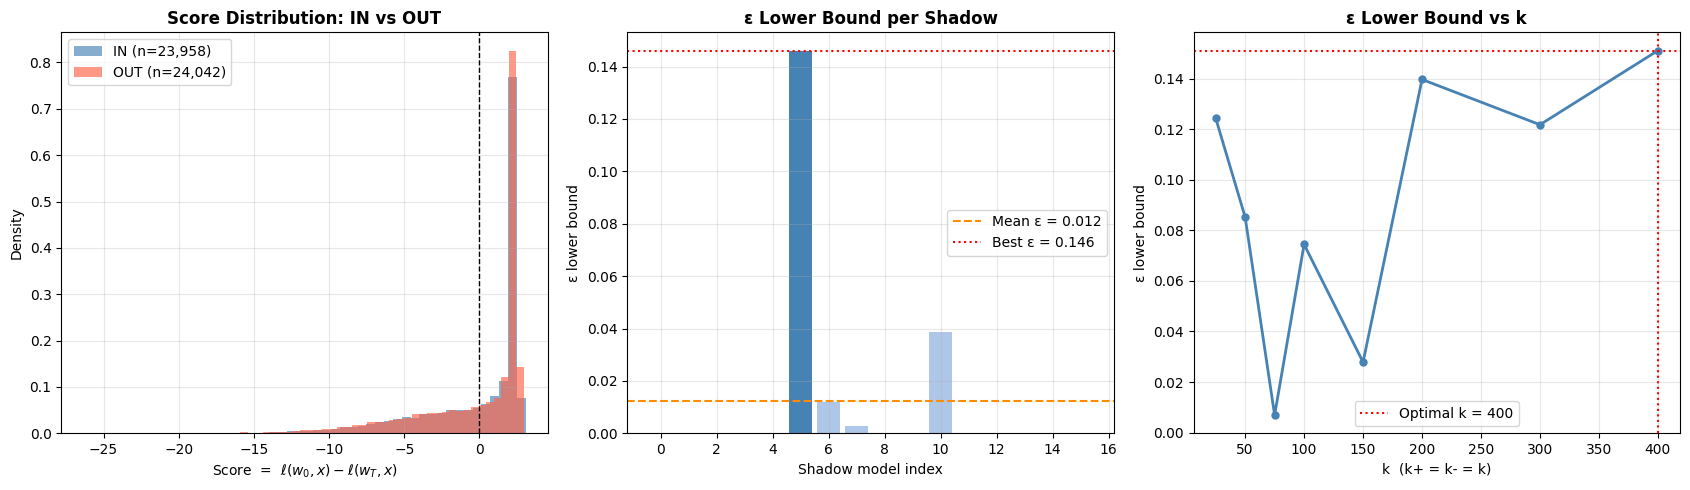

In [41]:
# ── 17. Figure 1: score distributions IN vs OUT ───────────────────────────────
import matplotlib.pyplot as plt

print("\nGenerating plots...\n")

# Aggregate scores and membership across all shadow models
all_in_scores = shadow_scores[membership].numpy()
all_out_scores = shadow_scores[~membership].numpy()

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# ── (a) Score distribution ──────────────────────────────────────────────────
ax = axes[0]
ax.hist(all_in_scores, bins=50, alpha=0.65, color="steelblue",
        label=f"IN (n={len(all_in_scores):,})", density=True)
ax.hist(all_out_scores, bins=50, alpha=0.65, color="tomato",
        label=f"OUT (n={len(all_out_scores):,})", density=True)
ax.axvline(0, color="black", lw=1.0, ls="--")
ax.set_title("Score Distribution: IN vs OUT", fontsize=12, fontweight="bold")
ax.set_xlabel(r"Score  =  $\ell(w_0, x) - \ell(w_T, x)$")
ax.set_ylabel("Density")
ax.legend()
ax.grid(alpha=0.3)

# ── (b) ε lower bound per shadow model ────────────────────────────────────
ax = axes[1]
colors = ["steelblue" if e == best_eps else "#aec6e8" for e in per_shadow_eps]
ax.bar(range(len(per_shadow_eps)), per_shadow_eps, color=colors)
ax.axhline(avg_eps, color="darkorange", lw=1.5, ls="--",
           label=f"Mean ε = {avg_eps:.3f}")
ax.axhline(best_eps, color="red", lw=1.5, ls=":",
           label=f"Best ε = {best_eps:.3f}")
ax.set_title("ε Lower Bound per Shadow", fontsize=12, fontweight="bold")
ax.set_xlabel("Shadow model index")
ax.set_ylabel("ε lower bound")
ax.legend()
ax.grid(alpha=0.3)

# ── (c) k-sweep curve ───────────────────────────────────────────────────────
ax = axes[2]
ax.plot(sweep_k, sweep_eps, marker="o", ms=5, color="steelblue", lw=2)
ax.axvline(best_k, color="red", ls=":", lw=1.5, label=f"Optimal k = {best_k}")
ax.axhline(best_eps_sweep, color="red", ls=":", lw=1.5)
ax.set_title("ε Lower Bound vs k", fontsize=12, fontweight="bold")
ax.set_xlabel("k  (k+ = k- = k)")
ax.set_ylabel("ε lower bound")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

# Save figure
fig_path = CFG["output_dir"] / "audit_results.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
print(f"✓ Figure saved → {fig_path}\n")

plt.show()

---
## § 10b — White-Box vs Black-Box Comparison Plots


✓ Comparison figure saved → audit_results/wb_vs_bb_audit_results.png


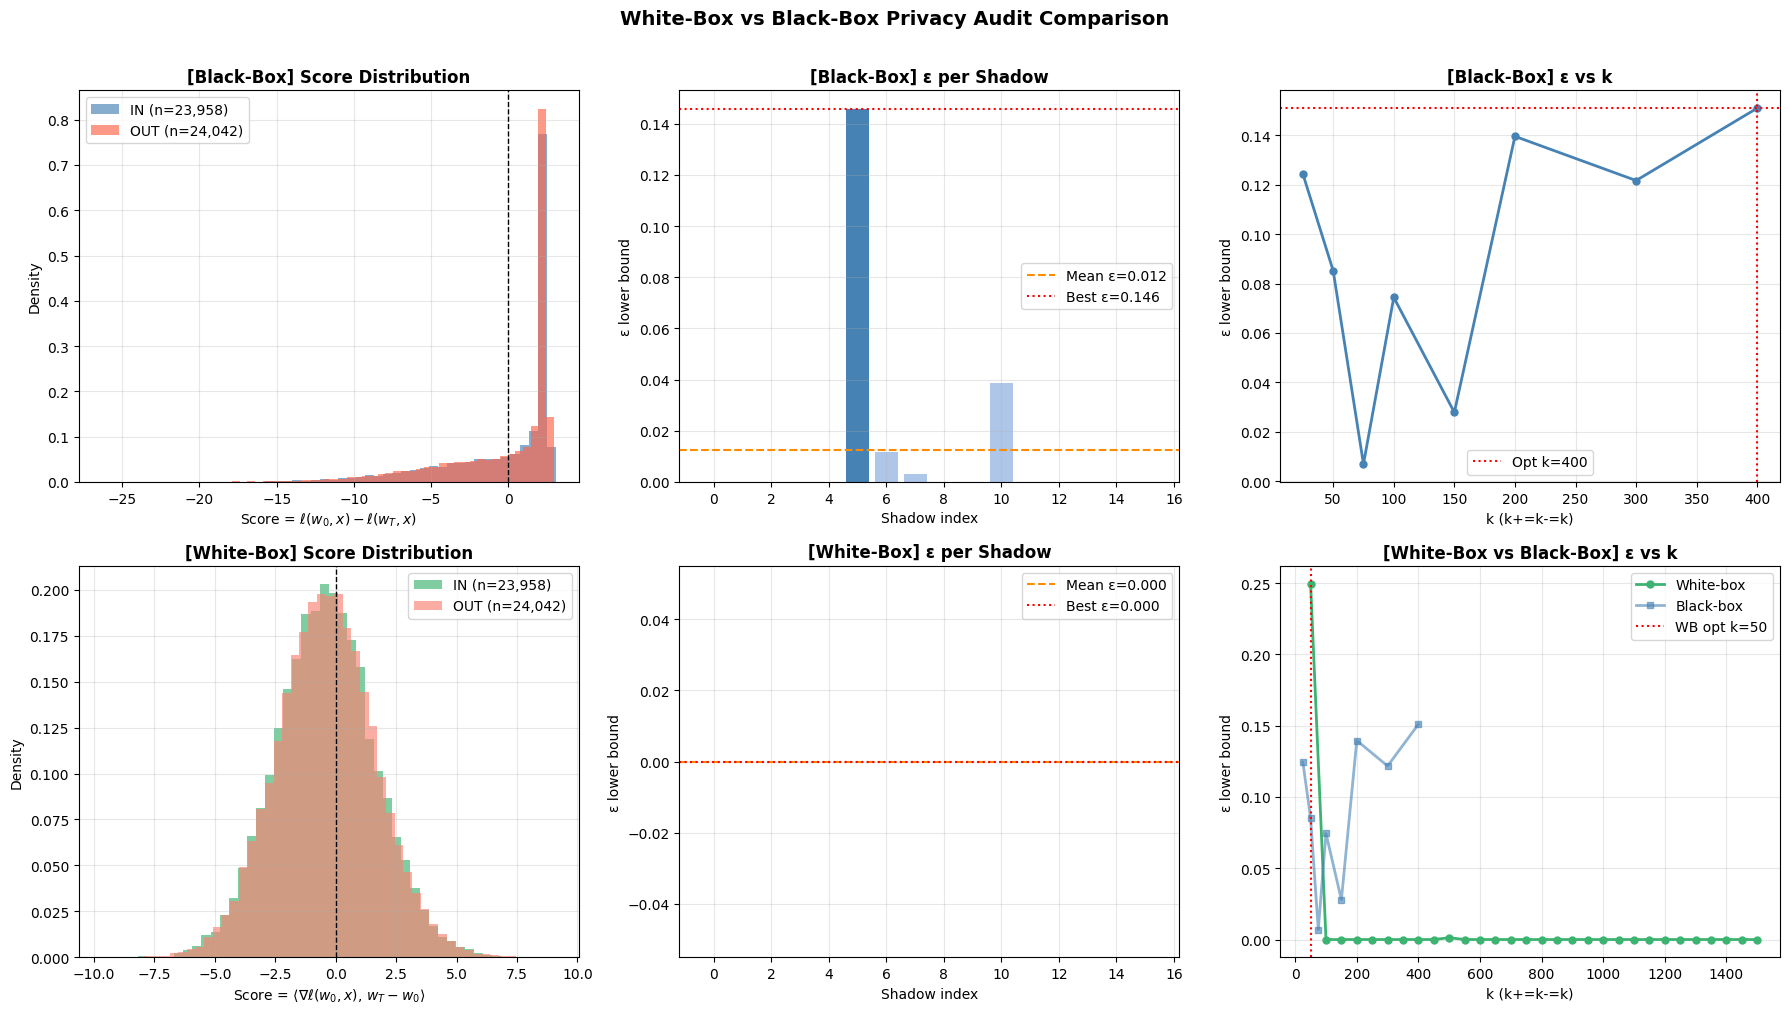

In [42]:
# ── Figure: WB vs BB comparison ───────────────────────────────────────────────
import matplotlib.pyplot as plt
import numpy as np

wb_in_scores  = wb_shadow_scores[wb_membership].numpy()
wb_out_scores = wb_shadow_scores[~wb_membership].numpy()

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("White-Box vs Black-Box Privacy Audit Comparison", fontsize=14, fontweight="bold", y=1.01)

# ── Row 0: Black-Box ──────────────────────────────────────────────────────────
# (a) BB score dist
ax = axes[0, 0]
ax.hist(all_in_scores,  bins=50, alpha=0.65, color="steelblue",
        label=f"IN (n={len(all_in_scores):,})",  density=True)
ax.hist(all_out_scores, bins=50, alpha=0.65, color="tomato",
        label=f"OUT (n={len(all_out_scores):,})", density=True)
ax.axvline(0, color="black", lw=1.0, ls="--")
ax.set_title("[Black-Box] Score Distribution", fontweight="bold")
ax.set_xlabel(r"Score = $\ell(w_0,x) - \ell(w_T,x)$")
ax.set_ylabel("Density")
ax.legend(); ax.grid(alpha=0.3)

# (b) BB ε per shadow
ax = axes[0, 1]
cols = ["steelblue" if e == best_eps else "#aec6e8" for e in per_shadow_eps]
ax.bar(range(len(per_shadow_eps)), per_shadow_eps, color=cols)
ax.axhline(avg_eps, color="darkorange", lw=1.5, ls="--", label=f"Mean ε={avg_eps:.3f}")
ax.axhline(best_eps, color="red",        lw=1.5, ls=":",  label=f"Best ε={best_eps:.3f}")
ax.set_title("[Black-Box] ε per Shadow", fontweight="bold")
ax.set_xlabel("Shadow index"); ax.set_ylabel("ε lower bound")
ax.legend(); ax.grid(alpha=0.3)

# (c) BB k-sweep
ax = axes[0, 2]
ax.plot(sweep_k, sweep_eps, marker="o", ms=5, color="steelblue", lw=2)
ax.axvline(best_k, color="red", ls=":", lw=1.5, label=f"Opt k={best_k}")
ax.axhline(best_eps_sweep, color="red", ls=":", lw=1.5)
ax.set_title("[Black-Box] ε vs k", fontweight="bold")
ax.set_xlabel("k (k+=k-=k)"); ax.set_ylabel("ε lower bound")
ax.legend(); ax.grid(alpha=0.3)

# ── Row 1: White-Box ──────────────────────────────────────────────────────────
# (d) WB score dist
ax = axes[1, 0]
ax.hist(wb_in_scores,  bins=50, alpha=0.65, color="mediumseagreen",
        label=f"IN (n={len(wb_in_scores):,})",  density=True)
ax.hist(wb_out_scores, bins=50, alpha=0.65, color="salmon",
        label=f"OUT (n={len(wb_out_scores):,})", density=True)
ax.axvline(0, color="black", lw=1.0, ls="--")
ax.set_title("[White-Box] Score Distribution", fontweight="bold")
ax.set_xlabel(r"Score = $\langle \nabla \ell(w_0,x),\, w_T - w_0 \rangle$")
ax.set_ylabel("Density")
ax.legend(); ax.grid(alpha=0.3)

# (e) WB ε per shadow
ax = axes[1, 1]
wb_best = max(wb_per_shadow_eps) if wb_per_shadow_eps else 0
cols_wb = ["mediumseagreen" if e == wb_best else "#a8d5b5" for e in wb_per_shadow_eps]
ax.bar(range(len(wb_per_shadow_eps)), wb_per_shadow_eps, color=cols_wb)
ax.axhline(wb_avg_eps,  color="darkorange", lw=1.5, ls="--", label=f"Mean ε={wb_avg_eps:.3f}")
ax.axhline(wb_best_eps, color="red",        lw=1.5, ls=":",  label=f"Best ε={wb_best_eps:.3f}")
ax.set_title("[White-Box] ε per Shadow", fontweight="bold")
ax.set_xlabel("Shadow index"); ax.set_ylabel("ε lower bound")
ax.legend(); ax.grid(alpha=0.3)

# (f) WB k-sweep
ax = axes[1, 2]
ax.plot(wb_sweep_k, wb_sweep_eps, marker="o", ms=5, color="mediumseagreen", lw=2, label="White-box")
ax.plot(sweep_k,    sweep_eps,    marker="s", ms=5, color="steelblue",      lw=2, label="Black-box", alpha=0.6)
ax.axvline(wb_best_k, color="red", ls=":", lw=1.5, label=f"WB opt k={wb_best_k}")
ax.set_title("[White-Box vs Black-Box] ε vs k", fontweight="bold")
ax.set_xlabel("k (k+=k-=k)"); ax.set_ylabel("ε lower bound")
ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout()
fig_path = CFG["output_dir"] / "wb_vs_bb_audit_results.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
print(f"✓ Comparison figure saved → {fig_path}")
plt.show()


---
## § 11 — Results Summary

In [43]:
# ── 18. Final summary table ──────────────────────────────────────────────────
import json
from opacus import PrivacyEngine
from opacus.validators import ModuleValidator

print("="*70)
print("PRIVACY AUDIT RESULTS (Steinke, Nasr & Jagielski 2023)")
print("="*70)

# ── Configuration Summary ──
print("\n── Configuration ──")
print(f"  Canaries (m)            : {CFG['num_canaries']}")
print(f"  Canary type             : {CFG['canary_type']}")
print(f"  Shadow models           : {CFG['num_shadow']}")
print(f"  Epochs / Batch size     : {CFG['num_epochs']} / {CFG['batch_size']}")
print(f"  Noise multiplier σ      : {CFG['noise_multiplier']}")
print(f"  Max grad norm c         : {CFG['max_grad_norm']}")
print(f"  δ                       : {CFG['delta']}")

# ── Score Separation ──
print("\n── Score Separation ──")
print(f"  IN  mean / std          : {all_in_scores.mean():+.4f} / {all_in_scores.std():.4f}")
print(f"  OUT mean / std          : {all_out_scores.mean():+.4f} / {all_out_scores.std():.4f}")
print(f"  Δ mean (IN − OUT)       : {all_in_scores.mean() - all_out_scores.mean():+.4f}")

# ── Audit Results (fixed k) ──
print("\n── Audit Results (fixed k) ──")
print(f"  k+ / k-                 : {CFG['k_plus']} / {CFG['k_minus']}")
print(f"  Best accuracy           : {max(per_shadow_acc):.4f}  (chance = 0.5000)")
print(f"  Avg  accuracy           : {np.mean(per_shadow_acc):.4f}")

# ── Audit Results (swept k) ──
print("\n── Audit Results (swept k) ──")
print(f"  Best k                  : {best_k}")
print(f"  Accuracy at best k      : {sweep_eps[sweep_k.index(best_k)]:.4f}")

# Compute theoretical ε using Opacus
print("\nComputing theoretical ε bound (Opacus)...")
try:
    from opacus import PrivacyEngine
    
    pe = PrivacyEngine()
    _m = build_model()
    _m = ModuleValidator.fix(_m)
    _opt = torch.optim.SGD(_m.parameters(), lr=0.01)
    
    _ds = NormDataset(data_gen.build_train_data(0), augment=False)
    _dl = torch.utils.data.DataLoader(
        _ds, batch_size=CFG["batch_size"], shuffle=True, num_workers=0
    )
    
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore")
        _, _, _ = pe.make_private(
            module=_m, optimizer=_opt, data_loader=_dl,
            noise_multiplier=CFG["noise_multiplier"],
            max_grad_norm=CFG["max_grad_norm"]
        )
    
    steps_per_epoch = len(_dl)
    sample_rate = CFG["batch_size"] / len(_ds)
    
    for _ in range(CFG["num_epochs"] * steps_per_epoch):
        pe.accountant.step(
            noise_multiplier=CFG["noise_multiplier"],
            sample_rate=sample_rate
        )
    
    theoretical_eps = pe.get_epsilon(CFG["delta"])
    del _m, _opt, _ds, _dl
    
except Exception as e:
    print(f"Warning: Could not compute theoretical ε: {e}")
    theoretical_eps = None

# ── Privacy Bounds ──
print("\n── Privacy Bounds ──")
if theoretical_eps:
    print(f"  ε upper bound (Opacus)  : ε ≤ {theoretical_eps:.4f}")
print(f"  ε lower bound (fixed k) : ε ≥ {best_eps:.4f}  (95% confidence)")
print(f"  ε lower bound (swept k) : ε ≥ {best_eps_sweep:.4f}  (best k={best_k})")
print(f"  Avg ε lower bound       : ε ≥ {avg_eps:.4f}")

if theoretical_eps:
    gap_lo = best_eps_sweep
    gap_hi = theoretical_eps
    print(f"  Privacy gap             : [{gap_lo:.4f}, {gap_hi:.4f}]")

# ── Save results to JSON ──
results = {
    "config": {k: str(v) for k, v in CFG.items()},
    "audit_results": {
        "best_eps_fixed_k": float(best_eps),
        "avg_eps_fixed_k": float(avg_eps),
        "best_eps_swept_k": float(best_eps_sweep),
        "best_k": int(best_k),
        "per_shadow_eps": [float(e) for e in per_shadow_eps],
        "per_shadow_acc": [float(a) for a in per_shadow_acc],
    },
    "score_statistics": {
        "in_mean": float(all_in_scores.mean()),
        "in_std": float(all_in_scores.std()),
        "out_mean": float(all_out_scores.mean()),
        "out_std": float(all_out_scores.std()),
        "delta_mean": float(all_in_scores.mean() - all_out_scores.mean()),
    },
}

if theoretical_eps:
    results["audit_results"]["theoretical_eps_upper_bound"] = float(theoretical_eps)

results_path = CFG["output_dir"] / "audit_results.json"
with open(results_path, "w") as f:
    json.dump(results, f, indent=2)

print(f"\n✓ Results saved → {results_path}")
print("="*70)

PRIVACY AUDIT RESULTS (Steinke, Nasr & Jagielski 2023)

── Configuration ──
  Canaries (m)            : 3000
  Canary type             : random_labels
  Shadow models           : 16
  Epochs / Batch size     : 150 / 4096
  Noise multiplier σ      : 1.5
  Max grad norm c         : 1.0
  δ                       : 1e-05

── Score Separation ──
  IN  mean / std          : -0.1998 / 3.6462
  OUT mean / std          : -0.3125 / 3.7223
  Δ mean (IN − OUT)       : +0.1126

── Audit Results (fixed k) ──
  k+ / k-                 : 450 / 450
  Best accuracy           : 0.5644  (chance = 0.5000)
  Avg  accuracy           : 0.5103

── Audit Results (swept k) ──
  Best k                  : 400
  Accuracy at best k      : 0.1511

Computing theoretical ε bound (Opacus)...

── Privacy Bounds ──
  ε upper bound (Opacus)  : ε ≤ 14.6336
  ε lower bound (fixed k) : ε ≥ 0.1458  (95% confidence)
  ε lower bound (swept k) : ε ≥ 0.1511  (best k=400)
  Avg ε lower bound       : ε ≥ 0.0124
  Privacy gap        

---
## § 11b — White-Box Results Summary


In [44]:
# ── Combined results summary: Black-Box vs White-Box ────────────────────────
import json
import numpy as np

print("=" * 70)
print("FINAL PRIVACY AUDIT RESULTS — BLACK-BOX vs WHITE-BOX")
print("(Steinke, Nasr & Jagielski 2023, Algorithms 1 & 2)")
print("=" * 70)

print("\n── Configuration ──")
for key in ("num_canaries", "canary_type", "num_shadow", "num_epochs",
            "batch_size", "noise_multiplier", "max_grad_norm", "delta"):
    print(f"  {key:25s}: {CFG[key]}")

print("\n── Score separation ──")
bb_delta = all_in_scores.mean() - all_out_scores.mean()
wb_delta = wb_in_scores.mean()  - wb_out_scores.mean()
print(f"  {'':25s}  {'Black-Box':>12}  {'White-Box':>12}")
print(f"  {'IN  mean / std':25s}: {all_in_scores.mean():+8.4f} / {all_in_scores.std():.4f}   {wb_in_scores.mean():+8.4f} / {wb_in_scores.std():.4f}")
print(f"  {'OUT mean / std':25s}: {all_out_scores.mean():+8.4f} / {all_out_scores.std():.4f}   {wb_out_scores.mean():+8.4f} / {wb_out_scores.std():.4f}")
print(f"  {'Δ mean (IN−OUT)':25s}: {bb_delta:+12.4f}   {wb_delta:+12.4f}")

print("\n── ε Lower Bounds (95% confidence) ──")
print(f"  {'':25s}  {'Black-Box':>12}  {'White-Box':>12}  {'Improvement':>12}")
print(f"  {'Best ε (fixed k)':25s}: {best_eps:12.4f}   {wb_best_eps:12.4f}   {wb_best_eps - best_eps:+12.4f}")
print(f"  {'Avg  ε (fixed k)':25s}: {avg_eps:12.4f}   {wb_avg_eps:12.4f}   {wb_avg_eps - avg_eps:+12.4f}")
print(f"  {'Best ε (swept k)':25s}: {best_eps_sweep:12.4f}   {wb_best_eps_sweep:12.4f}   {wb_best_eps_sweep - best_eps_sweep:+12.4f}")
print(f"  {'Optimal k':25s}: {best_k:12d}   {wb_best_k:12d}")

print("\n── Interpretation ──")
if wb_best_eps_sweep > best_eps_sweep:
    pct = 100 * (wb_best_eps_sweep - best_eps_sweep) / max(best_eps_sweep, 1e-9)
    print(f"  ✓ White-box improved the ε lower bound by {pct:.1f}%.")
    print(f"    This means the true ε is provably at least {wb_best_eps_sweep:.4f}.")
else:
    print(f"  White-box did not improve over black-box at this shadow count.")
    print(f"  Try increasing num_shadow or num_canaries.")

# ── Save combined results ────────────────────────────────────────────────────
combined = {
    "config": {k: str(v) for k, v in CFG.items()},
    "black_box": {
        "best_eps_fixed_k":  float(best_eps),
        "avg_eps_fixed_k":   float(avg_eps),
        "best_eps_swept_k":  float(best_eps_sweep),
        "best_k":            int(best_k),
        "per_shadow_eps":    [float(e) for e in per_shadow_eps],
        "in_mean":           float(all_in_scores.mean()),
        "out_mean":          float(all_out_scores.mean()),
    },
    "white_box": {
        "best_eps_fixed_k":  float(wb_best_eps),
        "avg_eps_fixed_k":   float(wb_avg_eps),
        "best_eps_swept_k":  float(wb_best_eps_sweep),
        "best_k":            int(wb_best_k),
        "per_shadow_eps":    [float(e) for e in wb_per_shadow_eps],
        "in_mean":           float(wb_in_scores.mean()),
        "out_mean":          float(wb_out_scores.mean()),
    },
}

out_path = CFG["output_dir"] / "wb_bb_audit_results.json"
with open(out_path, "w") as f:
    json.dump(combined, f, indent=2)

print(f"\n✓ Combined results saved → {out_path}")
print("=" * 70)


FINAL PRIVACY AUDIT RESULTS — BLACK-BOX vs WHITE-BOX
(Steinke, Nasr & Jagielski 2023, Algorithms 1 & 2)

── Configuration ──
  num_canaries             : 3000
  canary_type              : random_labels
  num_shadow               : 16
  num_epochs               : 150
  batch_size               : 4096
  noise_multiplier         : 1.5
  max_grad_norm            : 1.0
  delta                    : 1e-05

── Score separation ──
                                Black-Box     White-Box
  IN  mean / std           :  -0.1998 / 3.6462    -0.4216 / 2.0398
  OUT mean / std           :  -0.3125 / 3.7223    -0.3906 / 2.0352
  Δ mean (IN−OUT)          :      +0.1126        -0.0310

── ε Lower Bounds (95% confidence) ──
                                Black-Box     White-Box   Improvement
  Best ε (fixed k)         :       0.1458         0.0000        -0.1458
  Avg  ε (fixed k)         :       0.0124         0.0000        -0.0124
  Best ε (swept k)         :       0.1511         0.2497        +0.0986
  

---
## § 12 — Tips for Scaling Up

| Goal | Change |
|---|---|
| Reproduce paper ε≈100 | `num_shadow=32, num_epochs=60, noise_multiplier=0.4, batch_size=1024` |
| Reproduce paper ε≈7 | `num_shadow=32, num_epochs=220, noise_multiplier=3.0, batch_size=4096` |
| Faster training | Increase `batch_size`, `augmult_factor=16`, `num_workers=8` |
| Parallelise shadow models | Run cell below to train in parallel using `multiprocessing` or `concurrent.futures` |
| Better audit signal | Use `canary_type="blank_images"` (strongest signal for DP-SGD) |

---
## § 12b — Tips for White-Box Auditing

| Goal | Recommendation |
|---|---|
| **Faster gradient computation** | Use `torch.func.grad` (PyTorch ≥ 2.0) with `vmap` for vectorised per-sample gradients — 10–50× speedup over the loop |
| **Reduce GPU memory** | Lower `mini_batch` in `compute_wb_scores_for_shadow` (default 16); or use gradient checkpointing |
| **Stronger signal** | Use `canary_type="blank_images"` — synthetic canaries with random colours and random labels are maximally out-of-distribution |
| **More shadow models** | Each additional shadow model gives an independent estimate; 32 shadows is typical for publication-quality bounds |
| **Gradient norm scaling** | Divide the dot product by `‖∇L(w_0, x)‖` to get a cosine-similarity score; can reduce variance at large ε |
| **Reproduce paper Table 1** | `num_shadow=32, noise_multiplier=1.5, num_epochs=150, batch_size=4096, num_canaries=3000` |
| **Checkpoint overhead** | White-box requires saving `w0_state.pt` (already done in `train_shadow_model`) — no extra training cost |

### Algorithm summary

```
Algorithm 2 — White-Box Audit (Steinke et al. 2023)
─────────────────────────────────────────────────────
Input:  m canaries, T shadow models, confidence p, privacy parameters (ε, δ)
Output: ε lower bound

For each shadow model t = 1 … T:
  1. Sample membership bits b_i ~ Bernoulli(0.5) for each canary i
  2. Train on D_train ∪ {x_i : b_i = 1}  with DP-SGD  →  w_T^(t)
  3. For each canary x_i:
       Score(x_i) = <∇_w L(w_0^(t), x_i),  w_T^(t) - w_0^(t)>
  4. Guess b̂_i = 1 iff Score(x_i) is among the top-k+ scores
            b̂_i = 0 iff Score(x_i) is among the bottom-k- scores
  5. Count correct guesses v = #{i : b̂_i = b_i}

Run Corollary 5.4 (binomial test) on (m, r=k+ +k-, v, δ)
→ Return largest ε s.t. p-value < p
```


In [ ]:
# ── 19. Optional: parallel training via ThreadPoolExecutor ───────────────────
# Uncomment to train all shadow models in parallel.
# Useful when num_shadow > num_GPUs and you have many CPU cores.
# Each model runs on DEVICE; for multi-GPU use torchrun instead.

# from concurrent.futures import ThreadPoolExecutor, as_completed
#
# def train_wrapper(s):
#     return s, train_shadow_model(s, CFG, data_gen, verbose=False)
#
# with ThreadPoolExecutor(max_workers=min(4, CFG["num_shadow"])) as pool:
#     futures = {pool.submit(train_wrapper, s): s for s in range(CFG["num_shadow"])}
#     for fut in tqdm.tqdm(as_completed(futures), total=CFG["num_shadow"]):
#         s, m = fut.result()
#         trained_models[s] = m
#         print(f"  shadow {s} done")
print("(Parallel training cell — uncomment to use)")